# 0. INTRODUCTION

# Does a movie have a divorce in it ?

**Author** : Léna Rebours

**Date** : October 16th 2024

I recently divorced my partner and i'm still sad about it. I want to watch a movie to change my mind but I don't want to watch a movie with a divorce in it.

**Objective** : Predict whether a movie will have a divorce in it based on its pitch

We have to deal with a **classification** problem.

# 1. LIBRARY IMPORT

In [917]:
!python -m spacy download en_core_web_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 MB 20.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [918]:
!pip install adjustText

In [919]:
import pandas as pd
import numpy as np
from nltk import bigrams
import string
import spacy
import torch
import matplotlib.pyplot as plt
import seaborn as sns

In [920]:
from transformers import BertModel, BertTokenizer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.metrics import precision_score
from sklearn.model_selection import GridSearchCV
from IPython.display import display
from sklearn.metrics import recall_score
from tabulate import tabulate
from google.colab import files

# 2. DATA IMPORT

In [921]:
uploaded = files.upload()

Saving Letterboxd_annotations - Letterboxd_annotations.csv to Letterboxd_annotations - Letterboxd_annotations (5).csv


In [922]:
df = pd.read_csv("Letterboxd_annotations - Letterboxd_annotations.csv")
df

,NOM,PRENOM,id,name,description,link,pstrN,pstrNF,pstrNH,pstrVisages,pstrContact,txtMarr,txtCheat,txtDivorce,txtRelAvant,txtRelPendant,love
0,ALAOUI BOUHAMID,Sara,1294927,Stone Age Stunts,A cave man gets up in the morning to walk arou...,https://a.ltrbxd.com/resized/film-poster/3/5/6...,2,2,0,0,0,0,0,0,0,0,1
1,ALAOUI BOUHAMID,Sara,1393413,Anarkali,"Prince Salim, son of Akbar falls in love with ...",https://a.ltrbxd.com/resized/film-poster/3/7/3...,1,1,0,0,0,1,0,0,1,0,2
2,ALAOUI BOUHAMID,Sara,1274166,Człowiek z M-3,A young doctor receives an allotment for a sta...,https://a.ltrbxd.com/resized/film-poster/1/4/9...,0,0,0,0,0,1,0,0,0,0,1
3,ALAOUI BOUHAMID,Sara,1013754,The Shape of Things,"Quiet, unassuming Adam is changing in a major ...",https://a.ltrbxd.com/resized/film-poster/3/7/6...,2,1,1,0,1,0,0,0,1,0,1
4,ALAOUI BOUHAMID,Sara,1041125,Love and Bullets,A Camorra boss fakes his own death in order to...,https://a.ltrbxd.com/resized/film-poster/3/9/9...,2,1,1,0,1,0,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2314,VIVIER--BARTE,Nina,1413542,Exposição,"During the pandemic, introverted painter Hélio...",https://a.ltrbxd.com/resized/film-poster/1/1/7...,1,0,1,0,0,0,0,0,0,0,0
2315,VIVIER--BARTE,Nina,1110049,Perfect One-Night Stand,I really want to have sex before I turn 21! Ji...,https://a.ltrbxd.com/resized/film-poster/5/8/9...,2,2,0,0,0,0,0,0,0,1,2
2316,VIVIER--BARTE,Nina,1082796,"Sakal, Sakali, Saklolo","Newlywed Jed and Angie this time, they have to...",https://a.ltrbxd.com/resized/film-poster/1/1/7...,16,7,9,0,1,0,1,0,1,1,1
2317,VIVIER--BARTE,Nina,1028392,Abbas in Flower,While working as an assistant to swindling dri...,https://a.ltrbxd.com/resized/film-poster/1/1/7...,2,0,2,1,0,0,0,0,0,1,2


This dataset (2024, N=2319) is a part of the Letterboxd database with added manual annotation. Each line presents a movie with its title (text), its summary (text), a link to its poster and other informations, as well as answers to love related questions on the movie (binary or ordinal variables), such has the presence of a divorce in the movie.

## 2.1. Data description of the variable to be predicted

In [923]:
# Remove rows where txtDivorce contains "?"
df = df[df['txtDivorce'] != '?']

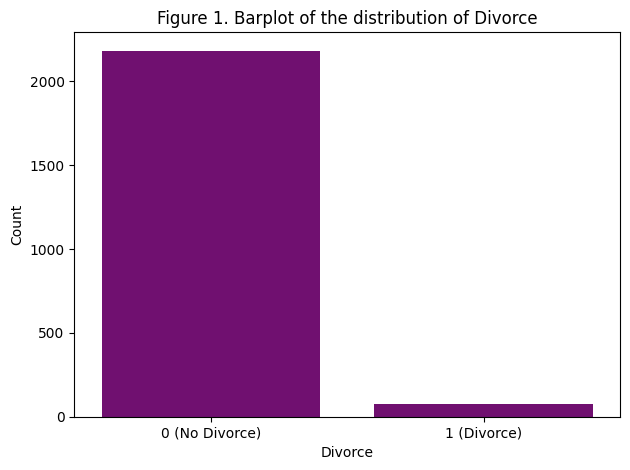

In [924]:
# Create the countplot
sns.countplot(x='txtDivorce', data=df, color="purple")

# Set title and labels for the axes
plt.title('Figure 1. Barplot of the distribution of Divorce')
plt.xlabel('Divorce')
plt.ylabel('Count')

# Update x-tick labels with the custom labels
plt.xticks(ticks=[0, 1], labels=['0 (No Divorce)', '1 (Divorce)'])

# Adjust layout to avoid overlap
plt.tight_layout()

# Display the plot
plt.show()


# 3. COMPUTE BAG OF WORDS

### 3.1. Specific bag of words

In [925]:
# Extract descriptions as a list
sentences = df['description'].tolist()

In [926]:
# List of divorce-related words
divorce_words = ["divorce", "divorced"]


In [927]:
# Function to remove punctuation and count specific word occurrences
def count_specific_words(sentence, words):
    sentence = sentence.translate(str.maketrans('', '', string.punctuation)).lower()
    sentence_words = sentence.split()
    return {word: sentence_words.count(word) for word in words}

In [928]:
# Create a DataFrame from the list of sentences and word counts
df = pd.DataFrame([count_specific_words(sentence, divorce_words) for sentence in sentences])

# Add the original sentences as a column in the DataFrame
df['sentence'] = sentences

# Reorder columns to put the sentence first
df = df[['sentence'] + divorce_words]

df

,sentence,divorce,divorced
0,A cave man gets up in the morning to walk arou...,0,0
1,"Prince Salim, son of Akbar falls in love with ...",0,0
2,A young doctor receives an allotment for a sta...,0,0
3,"Quiet, unassuming Adam is changing in a major ...",0,0
4,A Camorra boss fakes his own death in order to...,0,0
...,...,...,...
2312,"During the pandemic, introverted painter Hélio...",0,0
2313,I really want to have sex before I turn 21! Ji...,0,0
2314,"Newlywed Jed and Angie this time, they have to...",0,0
2315,While working as an assistant to swindling dri...,0,0


### 3.2 Generic bag of words

In [929]:
# Function to remove punctuation and count all word occurrences
def count_all_words(sentence):
    # Remove punctuation, convert to lowercase, and split into words
    sentence = sentence.translate(str.maketrans('', '', string.punctuation)).lower()
    sentence_words = sentence.split()  # Split the sentence into words
    return {word: sentence_words.count(word) for word in set(sentence_words)}

In [930]:
# Create a list of dictionaries for each sentence's word count
word_counts = [count_all_words(sentence) for sentence in sentences]

# Create a DataFrame from the word counts, filling missing words with 0
df = pd.DataFrame(word_counts).fillna(0).astype(int)

# Add the original sentences as a column in the DataFrame
df['sentence'] = sentences

# Reorder columns to put the sentence first
df = df[['sentence'] + [col for col in df.columns if col != 'sentence']]

df

,sentence,in,another,uses,saw,things,huge,prize,girl,man,dinos,saws,of,him,pretty,but,cold,the,on,around,out,stiff,teeth,his,neanderthal,bones,a,after,she,morning,body,back,wins,as,battles,to,gets,walk,he,knocking,with,club,cave,using,hitting,for,up,dinosaur,spiny,son,this,and,rajput,harmony,falls,strengthen,prolong,prince,salim,wanted,anarkali,communal,princess,forbids,marry,thereby,akbar,affair,love,wife,stateowned,young,begins,search,have,doctor,receives,frantic,right,flat,couples,only,an,type,married,so,disfortune,allotment,m3,adams,thanks,art,are,unassuming,friends,way,little,freaked,evelyn,transformation,by,adam,girlfriend,student,major,new,is,changing,quiet,family,nurse,rid,protect,alive,life,fakes,funeral,decides,get,himself,that,elsewhere,well,happens,start,promptly,shes,find,her,own,order,target,boss,camorra,sent,see,hitman,becoming,unforgotten,first,death,freedom,fellow,it,often,waiting,seducing,has,when,spending,unique,disappear,karma,all,moments,due,carelessness,citizens,girls,hes,still,parisian,realizing,come,loving,misunderstood,usually,debts,paris,ziggy,contrary,coppola,though,theres,two,peace,fall,other,belonging,each,fuel,village,will,result,enmity,rival,romance,youngsters,or,factions,add,surgeon,patient,jeanpierre,problems,serious,what,finds,heart,brilliant,disease,dont,dearest,discovers,be,which,operating,nearest,needs,interest,too,lovers,particularly,good,mourning,divorcée,grieving,break,reunite,daughter,they,widow,not,again,circumstances,strange,meet,time,recent,companys,mother,lindsay,doctors,enters,director,publishing,complicated,jack,scalia,novelist,who,into,wagner,marketing,terms,relationship,supernatural,couple,pessimistic,their,despite,outlook,something,tests,struggle,european,school,returns,colonel,over,had,killing,innocence,accused,whom,finishing,from,prove,feud,help,kentucky,money,about,parents,together,children,film,house,gather,build,bargain,hearts,unexpected,romantic,holiday,sammis,comedy,christmas,than,seth,season,interrupts,unknowingly,getaway,at,cabin,finding,more,newspaper,loyal,five,ideas,assistant,one,been,francis,finally,charming,takes,years,accepted,valley,past,sunflower,story,assignment,hometown,kate,seattle,earth,street,end,gonna,beto,theyre,punk,august,last,infused,skaters,day,herself,them,sow,prefer,hangs,farmer,piglets,pig,kills,mutant,mad,business,dealing,production,films,main,producer,runner,was,become,involved,secure,now,pornographic,asks,however,drug,moves,steal,town,elementary,high,awkward,nemesis,tries,shell,forced,boy,involving,politician’s,take,locality,issues,kidnapping,series,aspire,face,control,between,encounters,night,physical,everdeepening,intense,passionate,alternating,motel,deep,offer,lingers,fleabitten,party,stand,innocent,seemingly,daniela,home,gesture,lovemaking,ride,shacked,powerful,singles,pair,emotional,bruno,conversation,onenight,santiago,connection,chile,ends,dating,happiness,las,vegas,kaplow,shelly,happy,attractive,natalie,losing,misfortune,jinx,innate,bernie,gamblers,ability,those,where,bring,works,belisario,waitress,arrangement,casino,imposing,world,blackandwhite,thought,forever,display,someone,dreams,factory,meets,escape,every,too…,until,colour,one’s,worker,koiwai,salaryman,away,feels,awakens,vending,emotions,yamashita,cant,everything,machine,just,checks,stocks,eyes,strong,adult,ayumu,may,muscular,proper,teenagers,office,like,tear,gave,best,k,debutant,most,support,neelam,true,rest,siblings,short,tried,tu,you,friend,directorial,understand,smt,never,beautiful,qualities,real,siddiqui,knows,give,guest,walks,friendship,appearance,understood,saalim,us,god,rishabh,loves,mila,daniel,guptathanks,aggarwal,actormodel,jo,diary,name,sixth,bear,narrated,called,schoolfriend,meaning,comes,old,writes,nicknamed,tenyear,staszek,consecutive,szustek,jozef,blacksmiths,since,germany,off,savannahs,retrieve,savannah,eventually,ocean,john,weeks,purse,promises,write,while,overseas,tyree,sergeant,pier,leave,dives,fallen,traditions,villagers,ages,oleg,disloyalty,myths,legend,far,coi

### 3.3. Generic bag of words, without stop words

In [931]:
# List of common English stopwords
stopwords = set([
    "a", "an", "the", "and", "or", "but", "if", "then", "so", "because", "as",
    "with", "on", "in", "at", "by", "for", "about", "against", "between",
    "to", "from", "up", "down", "out", "over", "under", "again", "further",
    "here", "there", "when", "where", "why", "how", "all", "any", "both",
    "each", "few", "more", "most", "other", "some", "such", "no", "nor",
    "not", "only", "own", "same", "so", "than", "too", "very", "his"
])

# Function to remove punctuation and count all word occurrences, excluding stopwords
def count_all_words_no_stopwords(sentence):
    # Remove punctuation, convert to lowercase, and split into words
    sentence = sentence.translate(str.maketrans('', '', string.punctuation)).lower()
    sentence_words = sentence.split()  # Split the sentence into words
    filtered_words = [word for word in sentence_words if word not in stopwords] # Remove stopwords from the word list
    return {word: filtered_words.count(word) for word in set(filtered_words)}


In [932]:
# Process each sentence and count words, excluding stopwords
word_counts = [count_all_words_no_stopwords(sentence) for sentence in sentences]

# Create a DataFrame from the word counts, filling missing words with 0
df = pd.DataFrame(word_counts).fillna(0).astype(int)

# Add the original sentences as a column in the DataFrame
df['sentence'] = sentences

# Reorder columns to put the sentence first
df = df[['sentence'] + [col for col in df.columns if col != 'sentence']]

df

,sentence,another,uses,saw,things,huge,prize,girl,man,dinos,saws,of,him,pretty,cold,around,teeth,stiff,neanderthal,bones,after,she,morning,body,back,wins,battles,gets,walk,he,knocking,club,cave,using,hitting,dinosaur,spiny,son,this,rajput,harmony,falls,strengthen,prolong,prince,salim,wanted,anarkali,communal,princess,forbids,marry,thereby,akbar,affair,love,wife,allotment,stateowned,have,married,doctor,receives,flat,couples,disfortune,right,frantic,type,young,begins,search,m3,adams,thanks,art,are,unassuming,friends,way,little,freaked,evelyn,transformation,adam,girlfriend,student,major,new,is,changing,quiet,family,nurse,rid,protect,alive,life,fakes,funeral,decides,get,himself,that,elsewhere,well,happens,start,promptly,shes,find,her,order,target,boss,camorra,sent,see,hitman,becoming,unforgotten,first,death,freedom,fellow,it,often,waiting,seducing,has,spending,unique,disappear,karma,moments,due,carelessness,citizens,hes,girls,still,parisian,realizing,come,loving,misunderstood,usually,debts,paris,ziggy,contrary,coppola,though,theres,will,belonging,result,enmity,fuel,rival,youngsters,romance,factions,two,village,fall,peace,add,surgeon,patient,jeanpierre,what,problems,serious,finds,heart,brilliant,disease,dont,dearest,discovers,be,which,operating,nearest,needs,interest,lovers,particularly,good,mourning,divorcée,grieving,break,reunite,daughter,they,widow,circumstances,strange,meet,time,recent,companys,mother,lindsay,doctors,enters,director,publishing,complicated,jack,scalia,novelist,who,marketing,into,wagner,terms,relationship,supernatural,couple,pessimistic,their,despite,outlook,something,tests,struggle,european,school,colonel,returns,had,killing,innocence,accused,whom,finishing,feud,prove,help,kentucky,money,parents,together,film,house,gather,build,children,bargain,hearts,unexpected,romantic,holiday,sammis,comedy,christmas,seth,season,interrupts,unknowingly,getaway,cabin,finding,newspaper,loyal,five,ideas,assistant,one,been,francis,finally,charming,takes,years,accepted,valley,sunflower,past,story,assignment,hometown,kate,seattle,punk,day,skaters,august,last,earth,street,gonna,theyre,end,beto,infused,herself,them,sow,prefer,hangs,farmer,piglets,pig,kills,mutant,mad,business,dealing,production,main,producer,runner,was,become,involved,secure,now,pornographic,asks,however,films,drug,elementary,moves,town,tries,steal,boy,high,awkward,nemesis,shell,forced,involving,politician’s,take,locality,issues,kidnapping,series,aspire,face,control,encounters,night,physical,everdeepening,intense,passionate,alternating,motel,deep,offer,lingers,fleabitten,stand,party,innocent,seemingly,daniela,home,gesture,lovemaking,ride,shacked,powerful,singles,pair,emotional,bruno,conversation,onenight,santiago,connection,chile,ends,dating,happiness,las,vegas,kaplow,shelly,happy,attractive,natalie,losing,misfortune,jinx,innate,bernie,gamblers,ability,those,bring,works,belisario,waitress,arrangement,casino,imposing,world,blackandwhite,thought,forever,display,someone,dreams,factory,meets,escape,every,too…,until,colour,one’s,worker,koiwai,salaryman,away,feels,awakens,vending,emotions,yamashita,cant,everything,machine,just,checks,stocks,eyes,strong,adult,ayumu,may,muscular,proper,teenagers,office,like,tear,gave,best,k,debutant,support,neelam,true,siblings,rest,short,tu,tried,you,friend,directorial,understand,smt,never,beautiful,qualities,real,siddiqui,knows,give,guest,walks,friendship,appearance,understood,saalim,us,god,rishabh,loves,mila,guptathanks,daniel,aggarwal,actormodel,jo,diary,name,sixth,bear,narrated,called,meaning,comes,old,writes,nicknamed,tenyear,staszek,consecutive,szustek,schoolfriend,jozef,blacksmiths,since,germany,off,savannahs,retrieve,savannah,eventually,ocean,john,weeks,purse,promises,write,while,overseas,tyree,sergeant,pier,leave,dives,fallen,traditions,villagers,ages,oleg,disloyalty,myths,legend,far,coincidence,also,infidelity,lime,anastasias,worse,lay,ancient,mark,tree,goes,middle,later,anastasia,learns,pavel,local,stories,buried,discovering,going,

### 3.4. Generic bag of most frequent words, without stopwords

In [933]:
# Process each sentence and count words, excluding stopwords
word_counts = [count_all_words_no_stopwords(sentence) for sentence in sentences]

# Create a DataFrame from the word counts, filling missing words with 0
df = pd.DataFrame(word_counts).fillna(0).astype(int)

# Add the original sentences as a column in the DataFrame
df['sentence'] = sentences

# Calculate total occurrences of each word across all sentences
word_totals = df.drop(columns=['sentence']).sum()

# Filter to keep only words that have at least 2 occurrences
words_to_keep = word_totals[word_totals >= 2].index.tolist()

# Filter the DataFrame to keep only these words
df2 = df[['sentence'] + words_to_keep]

df2

sentence  another  uses  saw  things  huge  prize  girl  man  of  him  pretty  cold  around  stiff  bones  after  she  morning  body  back  wins  battles  gets  walk  he  knocking  club  cave  using  hitting  son  this  harmony  falls  prince  salim  wanted  princess  forbids  marry  thereby  akbar  affair  love  wife  have  married  doctor  receives  flat  couples  right  type  young  begins  search  m3  adams  thanks  art  are  friends  way  little  evelyn  transformation  adam  girlfriend  student  major  new  is  changing  quiet  family  nurse  rid  protect  alive  life  fakes  funeral  decides  get  himself  that  elsewhere  well  happens  start  promptly  shes  find  her  order  target  boss  sent  see  hitman  becoming  first  death  freedom  fellow  it  often  waiting  seducing  has  spending  unique  moments  due  carelessness  citizens  hes  girls  still  parisian  realizing  come  loving  misunderstood  usually  debts  paris  \
0     A cave man gets up in the morning to walk arou...        1     2    1       1     1      1     1    1   1    1       1     1       1      1      1      2    1        1     1     1     1        1     1     1   3         1     2     2      1        1    0     0        0      0       0      0       0         0        0      0        0      0       0     0     0     0        0       0         0     0        0      0     0      0       0       0   0      0       0    0    0        0    0       0       0               0     0           0        0      0    0   0         0      0       0      0    0        0      0     0      0        0        0    0        0     0          0     0        0      0         0     0     0    0      0       0     0     0    0       0         0      0      0        0       0   0      0        0         0    0         0       0        0    0             0         0    0      0      0         0          0     0       0              0        0      0      0   
1     Prince Salim, son of Akbar falls in love with ...        0     0    0       0     0      0     0    0   1    0       0     0       0      0      0      0    0        0     0     0     0        0     0     0   1         0     0     0      0        0    2     1        1      1       1      2       1         1        1      1        1      2       1     1     0     0        0       0         0     0        0      0     0      0       0       0   0      0       0    0    0        0    0       0       0               0     0           0        0      0    0   0         0      0       0      0    0        0      0     0      0        0        0    0        0     0          0     0        0      0         0     0     0    0      0       0     0     0    0       0         0      0      0        0       0   0      0        0         0    0         0       0        0    0             0         0    0      0      0         0          0     0       0              0        0      0      0   
2     A young doctor receives an allotment for a sta...        0     0    0       0     0      0     0    0   0    0       0     0       0      0      0      0    0        0     0     0     0        0     0     0   1         0     0     0      0        0    0     0        0      0       0      0       0         0        0      0        0      0       0     0     1     1        1       1         1     1        1      1     1      1       1       1   2      0       0    0    0        0    0       0       0               0     0           0        0      0    0   0         0      0       0      0    0        0      0     0      0        0        0    0        0     0          0     0        0      0         0     0     0    0      0       0     0     0    0       0         0      0      0        0       0   0      0        0         0    0         0       0        0    0             0         0    0      0      0         0          0     0       0              0        0      0      0   
3     Quiet, unassuming Adam is changing in a m

# 4. WORD EMBEDDINGS

### 4.1. Initialize models and tokenizer

In [934]:
nlp = spacy.load('en_core_web_md')


In [935]:
df = pd.read_csv("Letterboxd_annotations - Letterboxd_annotations.csv")

In [936]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased') # Using BERT model for sentence embeddings
model = BertModel.from_pretrained('bert-base-uncased')

### 4.2. Calculate the word embeddings for each texts and average them

In [937]:
def average_word_embedding(text):
    doc = nlp(text)
    word_embeddings = [token.vector for token in doc]
    if word_embeddings:
        return sum(word_embeddings) / len(word_embeddings)
    else:
        return [0] * 300  # spaCy uses 300-dimensional embeddings

df['Average Word Embedding'] = df['description'].apply(average_word_embedding)

In [938]:
# Expand the averaged word embeddings into separate columns
word_embedding_cols = pd.DataFrame(df['Average Word Embedding'].tolist(), index=df.index)
word_embedding_cols.columns = [f'Average_Word_Embedding_{i+1}' for i in range(300)]

In [939]:
# Concatenate the word embedding columns to the DataFrame
df = pd.concat([df, word_embedding_cols], axis=1)

# Drop the temporary 'Average Word Embedding' column
df = df.drop(columns=['Average Word Embedding'])


In [940]:
df

,NOM,PRENOM,id,name,description,link,pstrN,pstrNF,pstrNH,pstrVisages,pstrContact,txtMarr,txtCheat,txtDivorce,txtRelAvant,txtRelPendant,love,Average_Word_Embedding_1,Average_Word_Embedding_2,Average_Word_Embedding_3,Average_Word_Embedding_4,Average_Word_Embedding_5,Average_Word_Embedding_6,Average_Word_Embedding_7,Average_Word_Embedding_8,Average_Word_Embedding_9,Average_Word_Embedding_10,Average_Word_Embedding_11,Average_Word_Embedding_12,Average_Word_Embedding_13,Average_Word_Embedding_14,Average_Word_Embedding_15,Average_Word_Embedding_16,Average_Word_Embedding_17,Average_Word_Embedding_18,Average_Word_Embedding_19,Average_Word_Embedding_20,Average_Word_Embedding_21,Average_Word_Embedding_22,Average_Word_Embedding_23,Average_Word_Embedding_24,Average_Word_Embedding_25,Average_Word_Embedding_26,Average_Word_Embedding_27,Average_Word_Embedding_28,Average_Word_Embedding_29,Average_Word_Embedding_30,Average_Word_Embedding_31,Average_Word_Embedding_32,Average_Word_Embedding_33,Average_Word_Embedding_34,Average_Word_Embedding_35,Average_Word_Embedding_36,Average_Word_Embedding_37,Average_Word_Embedding_38,Average_Word_Embedding_39,Average_Word_Embedding_40,Average_Word_Embedding_41,Average_Word_Embedding_42,Average_Word_Embedding_43,Average_Word_Embedding_44,Average_Word_Embedding_45,Average_Word_Embedding_46,Average_Word_Embedding_47,Average_Word_Embedding_48,Average_Word_Embedding_49,Average_Word_Embedding_50,Average_Word_Embedding_51,Average_Word_Embedding_52,Average_Word_Embedding_53,Average_Word_Embedding_54,Average_Word_Embedding_55,Average_Word_Embedding_56,Average_Word_Embedding_57,Average_Word_Embedding_58,Average_Word_Embedding_59,Average_Word_Embedding_60,Average_Word_Embedding_61,Average_Word_Embedding_62,Average_Word_Embedding_63,Average_Word_Embedding_64,Average_Word_Embedding_65,Average_Word_Embedding_66,Average_Word_Embedding_67,Average_Word_Embedding_68,Average_Word_Embedding_69,Average_Word_Embedding_70,Average_Word_Embedding_71,Average_Word_Embedding_72,Average_Word_Embedding_73,Average_Word_Embedding_74,Average_Word_Embedding_75,Average_Word_Embedding_76,Average_Word_Embedding_77,Average_Word_Embedding_78,Average_Word_Embedding_79,Average_Word_Embedding_80,Average_Word_Embedding_81,Average_Word_Embedding_82,Average_Word_Embedding_83,Average_Word_Embedding_84,Average_Word_Embedding_85,Average_Word_Embedding_86,Average_Word_Embedding_87,Average_Word_Embedding_88,Average_Word_Embedding_89,Average_Word_Embedding_90,Average_Word_Embedding_91,Average_Word_Embedding_92,Average_Word_Embedding_93,Average_Word_Embedding_94,Average_Word_Embedding_95,Average_Word_Embedding_96,Average_Word_Embedding_97,Average_Word_Embedding_98,Average_Word_Embedding_99,Average_Word_Embedding_100,Average_Word_Embedding_101,Average_Word_Embedding_102,Average_Word_Embedding_103,Average_Word_Embedding_104,Average_Word_Embedding_105,Average_Word_Embedding_106,Average_Word_Embedding_107,Average_Word_Embedding_108,Average_Word_Embedding_109,Average_Word_Embedding_110,Average_Word_Embedding_111,Average_Word_Embedding_112,Average_Word_Embedding_113,Average_Word_Embedding_114,Average_Word_Embedding_115,Average_Word_Embedding_116,Average_Word_Embedding_117,Average_Word_Embedding_118,Average_Word_Embedding_119,Average_Word_Embedding_120,Average_Word_Embedding_121,Average_Word_Embedding_122,Average_Word_Embedding_123,Average_Word_Embedding_124,Average_Word_Embedding_125,Average_Word_Embedding_126,Average_Word_Embedding_127,Average_Word_Embedding_128,Average_Word_Embedding_129,Average_Word_Embedding_130,Average_Word_Embedding_131,Average_Word_Embedding_132,Average_Word_Embedding_133,Average_Word_Embedding_134,Average_Word_Embedding_135,Average_Word_Embedding_136,Average_Word_Embedding_137,Average_Word_Embedding_138,Average_Word_Embedding_139,Average_Word_Embedding_140,Average_Word_Embedding_141,Average_Word_Embedding_142,Average_Word_Embedding_143,Average_Word_Embedding_144,Average_Word_Embedding_145,Average_Word_Embedding_146,Average_Word_Embedding_147

### 4.3. Compute the sentence embeddings using a sentence embedding model

In [941]:
def get_sentence_embedding(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, padding=True, max_length=512)
    outputs = model(**inputs)
    # Use the CLS token representation as the sentence embedding
    sentence_embedding = outputs.last_hidden_state[:, 0, :].detach().numpy()
    return sentence_embedding.flatten()

df['Sentence Embedding'] = df['description'].apply(get_sentence_embedding)

In [942]:
 #Expand the sentence embeddings into separate columns (using pd.concat for performance)
sentence_embedding_size = model.config.hidden_size  # BERT hidden size (usually 768)
sentence_embedding_cols = pd.DataFrame(df['Sentence Embedding'].tolist(), index=df.index)
sentence_embedding_cols.columns = [f'Sentence_Embedding_{i+1}' for i in range(sentence_embedding_size)]

In [943]:
# Concatenate the sentence embedding columns to the DataFrame
df = pd.concat([df, sentence_embedding_cols], axis=1)

# Drop the temporary 'Sentence Embedding' column
df = df.drop(columns=['Sentence Embedding'])

In [944]:
df

NOM PRENOM       id                               name                                        description                                               link pstrN pstrNF pstrNH pstrVisages pstrContact txtMarr txtCheat txtDivorce txtRelAvant txtRelPendant love  Average_Word_Embedding_1  Average_Word_Embedding_2  Average_Word_Embedding_3  Average_Word_Embedding_4  Average_Word_Embedding_5  Average_Word_Embedding_6  Average_Word_Embedding_7  Average_Word_Embedding_8  Average_Word_Embedding_9  Average_Word_Embedding_10  Average_Word_Embedding_11  Average_Word_Embedding_12  Average_Word_Embedding_13  Average_Word_Embedding_14  Average_Word_Embedding_15  Average_Word_Embedding_16  Average_Word_Embedding_17  Average_Word_Embedding_18  Average_Word_Embedding_19  Average_Word_Embedding_20  Average_Word_Embedding_21  Average_Word_Embedding_22  Average_Word_Embedding_23  Average_Word_Embedding_24  Average_Word_Embedding_25  Average_Word_Embedding_26  Average_Word_Embedding_27  \
0     ALAOUI BOUHAMID   Sara  1294927                   Stone Age Stunts  A cave man gets up in the morning to walk arou...  https://a.ltrbxd.com/resized/film-poster/3/5/6...     2      2      0           0           0       0        0          0           0             0    1                 -1.718504                  1.140831                 -2.069659                  0.079738                  4.570847                  0.209128                 -0.500225                  5.709383                  1.863007                   0.366252                   6.000862                   1.142006                  -2.188854                   1.717323                   1.901827                   1.792940                   1.384602                  -1.135995                   0.475540                  -1.347829                   1.989657                  -0.843131                  -0.194973                  -1.417983                   0.096642                  -1.811512                  -4.009165   
1     ALAOUI BOUHAMID   Sara  1393413                           Anarkali  Prince Salim, son of Akbar falls in love with ...  https://a.ltrbxd.com/resized/film-poster/3/7/3...     1      1      0           0           0       1        0          0           1             0    2                 -1.836413                  1.441706                 -2.381327                 -1.256838                  4.370890                  0.109320                  0.693794                  3.698038                  0.692011                  -0.765043                   6.083915                   0.929896                  -1.547232                   1.947930                   1.795315                   0.753846                  -0.034898                  -2.152694                  -1.701653                  -1.151390                   0.661272                  -1.287743                  -1.414167                   0.299793                   1.282780                  -2.049437                  -2.078910   
2     ALAOUI BOUHAMID   Sara  1274166                     Człowiek z M-3  A young doctor receives an allotment for a sta...  https://a.ltrbxd.com/resized/film-poster/1/4/9...     0      0      0           0           0       1        0          0           0             0    1                 -1.912823                  2.817868                 -1.863061                 -0.329984                  4.064991                 -0.552199                  1.154045                  4.987884                  0.802287                  -0.004331                   6.119651                   0.929790                  -2.403227                   0.572427                   0.377402                   2.186329                   2.532521                  -0.033010                  -1.352553                  -1.402535                   0.069609                  -0.112891                  -0.883737                   0.902015                   1.225793                  -3.983977                  -3.678758   
3     ALAOUI B




---


# 5. DIVORCE PREDICTION

## 5.1. Functions

In [945]:
def plot_sorted_coefficients(coef, ax, threshold=1e-08):
    """
    Plots a sorted scatter plot of logistic regression coefficients with different colors
    for positive, negative, and near-zero coefficients.

    Parameters:
    - coef: A pandas Series or array-like object containing coefficients.
    - top_n: Number of top coefficients to plot based on absolute value. Default is 40.
    - threshold: A float value used to classify near-zero coefficients. Default is 1e-08.
    """

    # Sort the coefficients by absolute value and select the top_n
    sorted_coef = coef.abs().sort_values(ascending=False).head(40)

    # Get the original coefficients in sorted order for coloring
    original_sorted_coef = coef.loc[sorted_coef.index]


    # Determine colors based on the sign and threshold
    colors = [
        'grey' if abs(c) < threshold else 'green' if c > 0 else 'red'
        for c in original_sorted_coef
    ]

    # Scatter plot for coefficients
    ax.scatter(sorted_coef.values, sorted_coef.index, color=colors, zorder=5)

    # Plot lines from the origin to the scatter points
    for i in range(len(sorted_coef)):
        ax.plot([0, sorted_coef.values[i]], [i, i], color='skyblue', lw=2)

    # Add vertical line at zero
    ax.axvline(x=0, color='gray', linestyle='--', linewidth=1)

    # Set labels and title
    ax.set_xlabel('Absolute Coefficient Value')
    ax.set_ylabel('Feature')


## 5.2. Data manipulation

### 5.2.1. Dataset of Bag of Words

In [946]:
# Read the CSV file
df1 = pd.read_csv("Letterboxd_annotations - Letterboxd_annotations.csv")

# Merge df and df2 using the 'txtDivorce' column from df and adding the other columns from df2
df3 = pd.concat([df1['txtDivorce'], df2], axis=1)

In [947]:
# Remove the 'sentence' column from the DataFrame df
df3 = df3.drop(columns=['sentence'])

In [948]:
# Convert non-numeric values to NaN and then drop those rows
df3 = df3.apply(pd.to_numeric, errors='coerce').dropna()

### 5.2.2. Dataset of Word Embeddings

In [949]:
# Keep the first occurrence of 'txtDivorce' and remove duplicates
df = df.loc[:, ~df.columns.duplicated()]

# List of columns to keep
# Keep 'txtDivorce' and all columns after the first 17
columns_to_keep = ['txtDivorce'] + list(df.columns[17:])

# Ensure 'txtDivorce' is in the columns to keep, even if it is within the first 17 columns
if 'txtDivorce' not in columns_to_keep:
    columns_to_keep.insert(0, 'txtDivorce')

# Create a DataFrame with only the columns to keep
df = df[columns_to_keep]


In [950]:
# Convert non-numeric values to NaN and then drop those rows
df = df.apply(pd.to_numeric, errors='coerce').dropna()

## 5.3. Data normalization

### 5.3.1. Normalization of Bag of words

In [951]:
cols = [col for col in df3.drop('txtDivorce', axis = 1).columns]

scaler = StandardScaler()
df3[cols] = pd.DataFrame(scaler.fit_transform(df3[cols]), index = df3.index)
df3

txtDivorce   another       uses        saw    things       huge      prize      girl       man        of       him     pretty       cold    around      stiff      bones     after       she    morning      body      back       wins    battles      gets       walk        he   knocking       club       cave      using    hitting       son      this    harmony     falls    prince      salim     wanted  princess    forbids     marry    thereby      akbar    affair      love      wife      have   married    doctor   receives       flat    couples     right       type     young    begins    search         m3      adams     thanks       art       are   friends       way    little     evelyn  transformation       adam  girlfriend   student      major       new        is   changing      quiet    family      nurse        rid    protect      alive      life      fakes    funeral   decides       get   himself      that  elsewhere      well   happens     start   promptly      shes      find  \
0            0.0  4.442153  19.391597  14.994670  5.808566  16.772377  19.373521  2.191982  1.888259 -0.099485  1.315696  12.660399  13.680887  5.855105  23.738155  33.585711  5.165546  0.634824  14.292401  8.476764  3.951894  12.228382  27.416540  3.559377  15.807874  2.606227  33.585711  17.941585  42.490470  13.141245  33.585711 -0.189872 -0.313536  -0.051617 -0.321745 -0.100583  -0.021049  -0.055765 -0.093491  -0.036474 -0.177289  -0.036474  -0.021049 -0.161283 -0.577952 -0.222206 -0.292472 -0.248540 -0.123502  -0.081777  -0.047109  -0.082353 -0.121987  -0.042126 -0.428012 -0.187773 -0.116039  -0.021049  -0.029775  -0.078986 -0.095887 -0.363274 -0.250889 -0.217002 -0.135939  -0.036474       -0.036474  -0.044687   -0.175676 -0.178920  -0.059628 -0.307845 -0.701276  -0.042126  -0.066696 -0.255197  -0.053314  -0.051617  -0.066696  -0.076096 -0.366073  -0.036474  -0.055765 -0.200409 -0.271765 -0.182042 -0.477625  -0.029775 -0.155141 -0.117983 -0.152125  -0.047109 -0.134311 -0.261134   
1            0.0 -0.195101  -0.094930  -0.053314 -0.166715  -0.044687  -0.051617 -0.314092 -0.356969 -0.099485 -0.399571  -0.078986  -0.073095 -0.165308  -0.042126  -0.029775 -0.368880 -0.445381  -0.069967 -0.102587 -0.221809  -0.081777  -0.036474 -0.206824  -0.063260  0.541726  -0.029775  -0.087832  -0.028245  -0.076096  -0.029775  7.605238  2.576114  19.373521  2.907144  5.306966  47.507894  17.932413  6.943270  27.416540  4.532349  27.416540  47.507894  5.808816  0.946599 -0.222206 -0.292472 -0.248540 -0.123502  -0.081777  -0.047109  -0.082353 -0.121987  -0.042126 -0.428012 -0.187773 -0.116039  -0.021049  -0.029775  -0.078986 -0.095887 -0.363274 -0.250889 -0.217002 -0.135939  -0.036474       -0.036474  -0.044687   -0.175676 -0.178920  -0.059628 -0.307845 -0.701276  -0.042126  -0.066696 -0.255197  -0.053314  -0.051617  -0.066696  -0.076096 -0.366073  -0.036474  -0.055765 -0.200409 -0.271765 -0.182042 -0.477625  -0.029775 -0.155141 -0.117983 -0.152125  -0.047109 -0.134311 -0.261134   
2            0.0 -0.195101  -0.094930  -0.053314 -0.166715  -0.044687  -0.051617 -0.314092 -0.356969 -0.863557 -0.399571  -0.078986  -0.073095 -0.165308  -0.042126  -0.029775 -0.368880 -0.445381  -0.069967 -0.102587 -0.221809  -0.081777  -0.036474 -0.206824  -0.063260  0.541726  -0.029775  -0.087832  -0.028245  -0.076096  -0.029775 -0.189872 -0.313536  -0.051617 -0.321745 -0.100583  -0.021049  -0.055765 -0.093491  -0.036474 -0.177289  -0.036474  -0.021049 -0.161283 -0.577952  3.578861  2.655751  3.517928  6.516182  12.228382  21.227341  10.856024  7.747902  23.738155  1.682143  4.576184  8.617811  47.507894  -0.029775  -0.078986 -0.095887 -0.363274 -0.250889 -0.217002 -0.135939  -0.036474       -0.036474  -0.044687   -0.175676 -0.178920  -0.059628 -0.307845 -0.701276  -0.042126  -0.066696 -0.255197  -0.053314  -0.051617  -0.066696  -0.076096 -0.366073  -0.036474  -0.055765 -0.200409 -0.271765 -0.182042 -0.477625  -0.029775 -0.155141 -0.117983 -0.152125  -0.047109 -0.134311 -0.261134   
3 

### 5.3.2. Normalization of Word Embeddings

In [952]:
cols = [col for col in df.drop('txtDivorce', axis = 1).columns]

scaler = StandardScaler()
df[cols] = pd.DataFrame(scaler.fit_transform(df[cols]), index = df.index)
df

txtDivorce  Average_Word_Embedding_1  Average_Word_Embedding_2  Average_Word_Embedding_3  Average_Word_Embedding_4  Average_Word_Embedding_5  Average_Word_Embedding_6  Average_Word_Embedding_7  Average_Word_Embedding_8  Average_Word_Embedding_9  Average_Word_Embedding_10  Average_Word_Embedding_11  Average_Word_Embedding_12  Average_Word_Embedding_13  Average_Word_Embedding_14  Average_Word_Embedding_15  Average_Word_Embedding_16  Average_Word_Embedding_17  Average_Word_Embedding_18  Average_Word_Embedding_19  Average_Word_Embedding_20  Average_Word_Embedding_21  Average_Word_Embedding_22  Average_Word_Embedding_23  Average_Word_Embedding_24  Average_Word_Embedding_25  Average_Word_Embedding_26  Average_Word_Embedding_27  Average_Word_Embedding_28  Average_Word_Embedding_29  Average_Word_Embedding_30  Average_Word_Embedding_31  Average_Word_Embedding_32  Average_Word_Embedding_33  Average_Word_Embedding_34  Average_Word_Embedding_35  Average_Word_Embedding_36  \
0            0.0                  0.194483                  0.302236                  0.014500                  0.655285                  0.159150                 -0.100803                 -2.083926                  1.484115                  1.311910                   1.092977                   0.475037                  -0.163574                   0.936991                   0.728607                   1.117624                   0.291853                   0.738040                  -0.563099                   2.028723                   0.092372                   1.428216                  -0.543585                   0.706470                  -1.136661                  -0.554749                   0.137204                  -1.102135                  -1.329230                   0.933670                   1.207355                  -1.155664                  -1.366651                   0.805912                  -0.613553                   0.063115                  -1.104523   
1            0.0                  0.044667                  0.609939                 -0.330267                 -1.265586                 -0.044196                 -0.248990                  0.008731                 -0.707001                  0.068635                  -0.436159                   0.550567                  -0.482814                   1.728541                   1.106638                   0.959541                  -1.243946                  -0.938058                  -1.380914                  -1.104195                   0.315428                  -0.723500                  -1.153487                  -0.892419                   0.658809                   1.023004                  -0.181003                   1.349760                   3.112184                  -1.756408                  -0.752441                   0.050636                  -1.377275                   0.128884                   0.056478                   0.401647                  -0.005955   
2            0.0                 -0.052420                  2.017326                  0.243038                  0.066449                 -0.355279                 -1.231162                  0.815373                  0.698130                  0.185718                   0.592072                   0.583066                  -0.482975                   0.672525                  -1.148203                  -1.144892                   0.873288                   2.093463                   0.324124                  -0.601849                   0.030253                  -1.681874                   0.458130                  -0.196796                   1.288269                   0.947202                  -2.768302                  -0.682437                  -0.288761                  -1.851004                  -1.418334                   0.177496                   0.095190                   0.520889                   1.561456                   0.264254                   1.596774   
3            0.0                 -0.085626                 -0.169667      

## 5.4. Train / Test split

### 5.4.1. Split for Bag of words

In [953]:
X = df3.drop("txtDivorce", axis = 1)
y = df3["txtDivorce"]

X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size = 0.2, random_state = 666)

### 5.4.2. Split for Word Embeddings

In [954]:
X = df.drop("txtDivorce", axis = 1)
y = df["txtDivorce"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 666)

## 5.5. Logistic Regression

### 5.5.1. Logistic Regression for Bag of Words

In [955]:
# Performing Logistic Regression
reg2 = LogisticRegression(max_iter = 10000)
reg2.fit(X_train2, y_train2)

coef2 = pd.Series(reg2.coef_.flatten(), index = X_train2.columns)

In [956]:
# Test the logistic regression
y_pred2 = reg2.predict(X_test2)

In [957]:
# Confusion matrix
cm = confusion_matrix(y_test2, y_pred2)
cm_df3 = pd.DataFrame(cm, index=['No Divorce', 'Divorce'], columns=['Predicted no divorce', 'Predicted divorce'])
print("Confusion Matrix:")
print(cm_df3)

Confusion Matrix:
            Predicted no divorce  Predicted divorce
No Divorce                   437                  0
Divorce                       15                  0


In [958]:
accuracy_score(y_test2, y_pred2)

0.9668141592920354

### 5.5.2 Logistic Regression for Word Embeddings

In [959]:
# Performing Logistic Regression
reg = LogisticRegression(max_iter = 10000)
reg.fit(X_train, y_train)

coef = pd.Series(reg.coef_.flatten(), index = X_train.columns)

In [960]:
# Test the logistic regression
y_pred = reg.predict(X_test)

In [961]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=['No Divorce', 'Divorce'], columns=['Predicted no divorce', 'Predicted divorce'])
print("Confusion Matrix:")
print(cm_df)

Confusion Matrix:
            Predicted no divorce  Predicted divorce
No Divorce                   423                 10
Divorce                       16                  3


In [962]:
accuracy_score(y_test, y_pred)

0.9424778761061947

### 5.5.3. Representation of Confusion Matrices and Coefficients

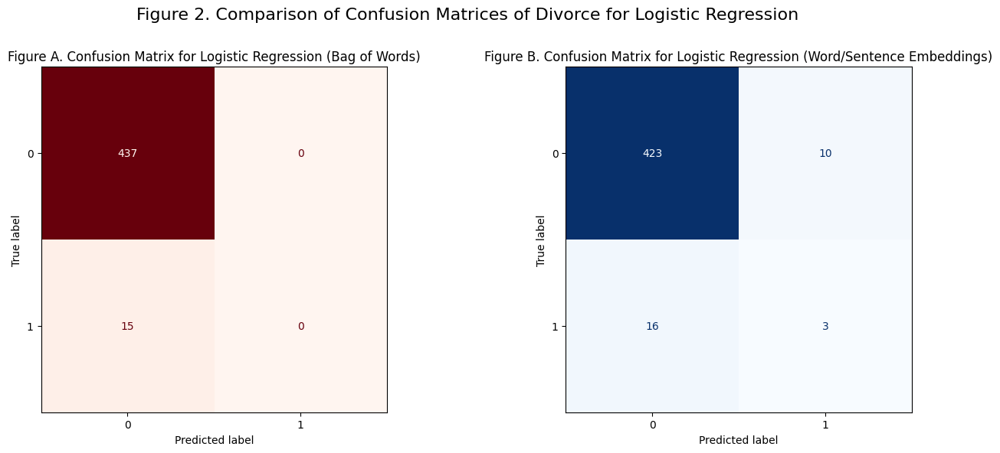

In [963]:
# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # Figure with two side-by-side plots

# Plot the first confusion matrix (in red)
cm1 = confusion_matrix(y_test2, y_pred2)
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm1)
disp1.plot(cmap='Reds', ax=axes[0], colorbar=False)
axes[0].set_title("Figure A. Confusion Matrix for Logistic Regression (Bag of Words)")

# Plot the second confusion matrix (in blue)
cm2 = confusion_matrix(y_test, y_pred)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2)
disp2.plot(cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title("Figure B. Confusion Matrix for Logistic Regression (Word/Sentence Embeddings)")

# Add a global title
fig.suptitle("Figure 2. Comparison of Confusion Matrices of Divorce for Logistic Regression", fontsize=16)

# Adjust spacing to avoid overlap and leave room for the title
plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()

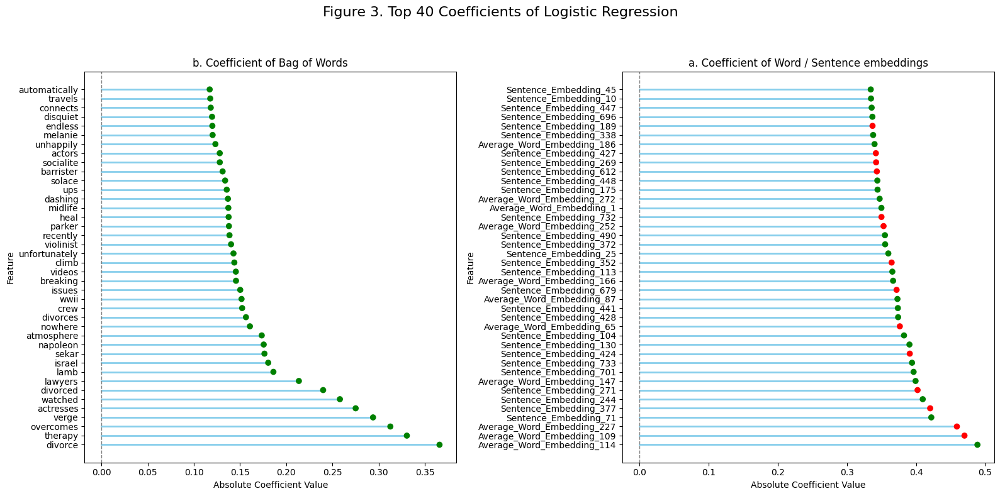

In [964]:
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))  # Create a panel with two side-by-side plots

# Plot the second coefficient graph (a. Coefficient of Word embeddings)
plot_sorted_coefficients(coef, axes[1])  # Plot the first coefficient graph (Word embeddings)

# Plot the first coefficient graph (b. Coefficient of Bag of Words)
plot_sorted_coefficients(coef2, axes[0])  # Plot the second coefficient graph (Bag of Words)

# Add a global title to the figure
fig.suptitle("Figure 3. Top 40 Coefficients of Logistic Regression", fontsize=16)

# Add subtitles to each graph
axes[1].set_title("a. Coefficient of Word / Sentence embeddings")
axes[0].set_title("b. Coefficient of Bag of Words")

# Display the plots
plt.tight_layout()
plt.subplots_adjust(top=0.85)  # Adjust spacing to make room for the global title
plt.show()

## 5.6. Neural Network

### 5.6.1. Neural Network for Bag of Words

In [965]:
# Large Neural Network with three hidden layers ([100,50] neurons)
clf_150_neurons_classification2 = MLPClassifier(
    hidden_layer_sizes=(100, 50),  # Three hidden layers with 100 and 50 neurons respectively
    activation='relu',  # ReLU activation function
    solver='adam',  # Adam optimizer
    max_iter=1000,  # Max iterations for training
    alpha=10,  # Regularization parameter
    tol=1e-6,  # Tolerance for stopping criterion
    batch_size=1000,  # Batch size for training
    random_state=666,  # Random seed for reproducibility
    verbose=True  # Display training progress
)

# Train the network on the training data
clf_150_neurons_classification2.fit(X_train2, y_train2)

# Predict on the test set
y_pred2 = clf_150_neurons_classification2.predict(X_test2)

Iteration 1, loss = 1.75272435
Iteration 2, loss = 1.47171697
Iteration 3, loss = 1.31810329
Iteration 4, loss = 1.18799334
Iteration 5, loss = 1.07050929
Iteration 6, loss = 0.96368291
Iteration 7, loss = 0.86813034
Iteration 8, loss = 0.78424646
Iteration 9, loss = 0.71132150
Iteration 10, loss = 0.64861512
Iteration 11, loss = 0.59561304
Iteration 12, loss = 0.55098376
Iteration 13, loss = 0.51345932
Iteration 14, loss = 0.48197157
Iteration 15, loss = 0.45545865
Iteration 16, loss = 0.43294332
Iteration 17, loss = 0.41364510
Iteration 18, loss = 0.39690094
Iteration 19, loss = 0.38218972
Iteration 20, loss = 0.36902364
Iteration 21, loss = 0.35709113
Iteration 22, loss = 0.34613936
Iteration 23, loss = 0.33598064
Iteration 24, loss = 0.32648739
Iteration 25, loss = 0.31754636
Iteration 26, loss = 0.30909627
Iteration 27, loss = 0.30108594
Iteration 28, loss = 0.29348711
Iteration 29, loss = 0.28623929
Iteration 30, loss = 0.27934464
Iteration 31, loss = 0.27274918
Iteration 32, los

In [966]:
# Confusion matrix
cm = confusion_matrix(y_test2, y_pred2)
cm_df3 = pd.DataFrame(cm, index=['Divorce', 'No Divorce'], columns=['Predicted Divrorce', 'Predicted No Divorce'])
print("Confusion Matrix:")
print(cm_df3)

Confusion Matrix:
            Predicted Divrorce  Predicted No Divorce
Divorce                    437                     0
No Divorce                  15                     0


In [967]:
accuracy_score(y_test2, y_pred2)

0.9668141592920354

### 5.6.2. Neural Network for Word / Sentence Embeddings

In [968]:
# Large Neural Network with three hidden layers ([100,50] neurons)
clf_150_neurons_classification = MLPClassifier(
    hidden_layer_sizes=(100, 50),  # Three hidden layers with 100 and 50 neurons respectively
    activation='relu',  # ReLU activation function
    solver='adam',  # Adam optimizer
    max_iter=1000,  # Max iterations for training
    alpha=10,  # Regularization parameter
    tol=1e-6,  # Tolerance for stopping criterion
    batch_size=1000,  # Batch size for training
    random_state=666,  # Random seed for reproducibility
    verbose=True  # Display training progress
)

# Train the network on the training data
clf_150_neurons_classification.fit(X_train, y_train)

# Predict on the test set
y_pred = clf_150_neurons_classification.predict(X_test)

Iteration 1, loss = 2.61427919
Iteration 2, loss = 1.98939962
Iteration 3, loss = 1.67831657
Iteration 4, loss = 1.53831276
Iteration 5, loss = 1.47298447
Iteration 6, loss = 1.43438267
Iteration 7, loss = 1.40278672
Iteration 8, loss = 1.37101820
Iteration 9, loss = 1.33556681
Iteration 10, loss = 1.29691180
Iteration 11, loss = 1.25618783
Iteration 12, loss = 1.21443735
Iteration 13, loss = 1.17282292
Iteration 14, loss = 1.13214640
Iteration 15, loss = 1.09306928
Iteration 16, loss = 1.05584567
Iteration 17, loss = 1.02016098
Iteration 18, loss = 0.98568994
Iteration 19, loss = 0.95174927
Iteration 20, loss = 0.91921900
Iteration 21, loss = 0.88853701
Iteration 22, loss = 0.85965330
Iteration 23, loss = 0.83163583
Iteration 24, loss = 0.80467900
Iteration 25, loss = 0.77868507
Iteration 26, loss = 0.75345855
Iteration 27, loss = 0.72954041
Iteration 28, loss = 0.70662205
Iteration 29, loss = 0.68472789
Iteration 30, loss = 0.66392979
Iteration 31, loss = 0.64393478
Iteration 32, los

In [969]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=['Divorce', 'No Divorce'], columns=['Predicted Divrorce', 'Predicted No Divorce'])
print("Confusion Matrix:")
print(cm_df)

Confusion Matrix:
            Predicted Divrorce  Predicted No Divorce
Divorce                    432                     1
No Divorce                  19                     0


In [970]:
accuracy_score(y_test, y_pred)

0.9557522123893806

### 5.6.3. Representation of Confusion Matrices and Loss Curve

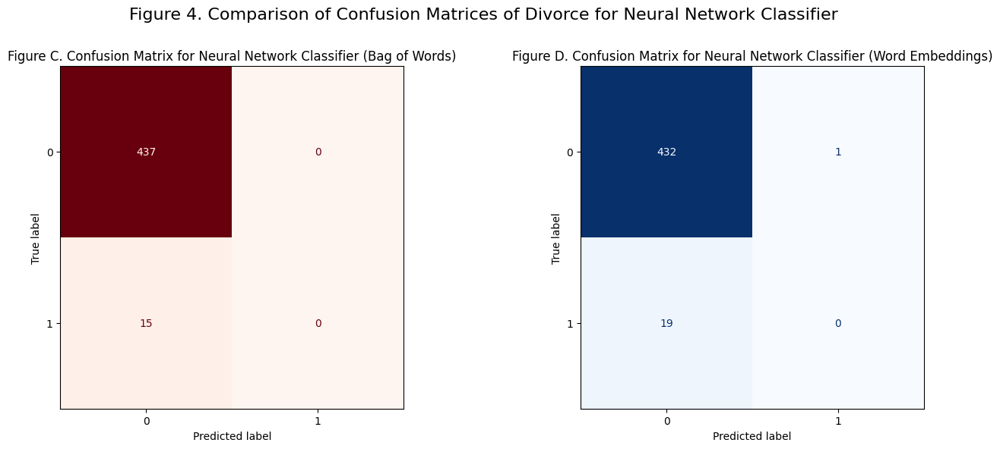

In [971]:
# Create a figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # Figure with two side-by-side plots

# Plot the first confusion matrix for the Neural Network Classifier (in red)
cm1 = confusion_matrix(y_test2, y_pred2)
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm1)
disp1.plot(cmap='Reds', ax=axes[0], colorbar=False)
axes[0].set_title("Figure C. Confusion Matrix for Neural Network Classifier (Bag of Words)")

# Plot the second confusion matrix for the Neural Network Classifier (in blue)
cm2 = confusion_matrix(y_test, y_pred)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2)
disp2.plot(cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title("Figure D. Confusion Matrix for Neural Network Classifier (Word Embeddings)")

# Add a global title
fig.suptitle("Figure 4. Comparison of Confusion Matrices of Divorce for Neural Network Classifier", fontsize=16)

# Adjust spacing to avoid overlap and leave room for the title
plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()


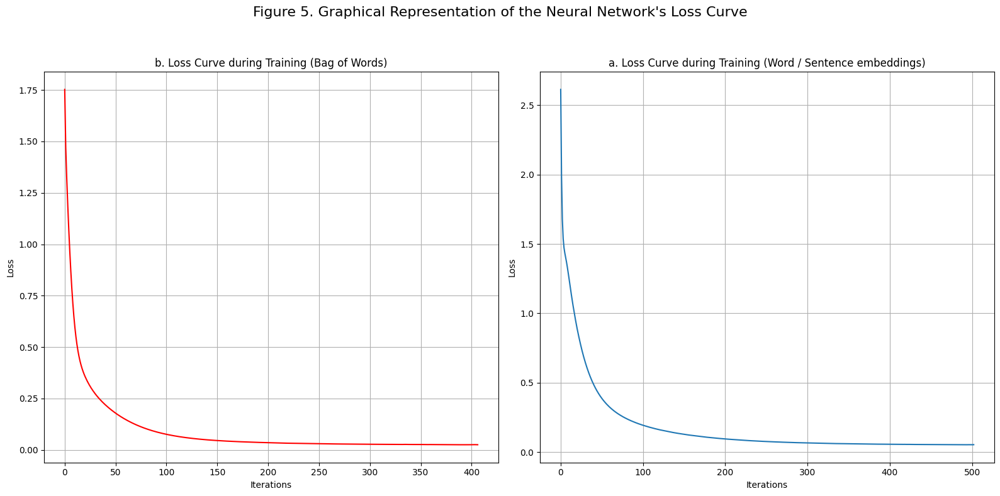

In [972]:
# Create a figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))  # Figure with two side-by-side plots

# Plot the second loss curve for clf_150_neurons_classification
axes[1].plot(clf_150_neurons_classification.loss_curve_)  # Use the loss_curve_ attribute
axes[1].set_title("a. Loss Curve during Training (Word / Sentence embeddings)")
axes[1].set_xlabel("Iterations")
axes[1].set_ylabel("Loss")
axes[1].grid(True)

# Plot the first loss curve for clf_150_neurons_classification2
axes[0].plot(clf_150_neurons_classification2.loss_curve_, color='red')  # Use the loss_curve_ attribute
axes[0].set_title("b. Loss Curve during Training (Bag of Words)")
axes[0].set_xlabel("Iterations")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

# Add a global title to the figure
fig.suptitle("Figure 5. Graphical Representation of the Neural Network's Loss Curve", fontsize=16)

# Adjust display to avoid overlap
plt.tight_layout()
plt.subplots_adjust(top=0.85)  # Adjust spacing to make room for the global title
plt.show()


# 6. DIAGNOSTIC

## 6.1. Performance Table

In [973]:
# Create a dictionary to store the accuracy values of each model

data = {
    "Model": ["Logistic Regression", "Neural Network"],
    "Bag of Words": [0.967, 0.967],  # Example accuracies for each model
    "Word and sentence embeddings": [0.942, 0.956]  # Example accuracies for each model
}

# Create the DataFrame
performance_df = pd.DataFrame(data)

# Display the table
print(performance_df)


                 Model  Bag of Words  Word and sentence embeddings
0  Logistic Regression         0.967                         0.942
1       Neural Network         0.967                         0.956


## 6.2. Diagnostic Table

We see a large disproportion between the number of films with divorces and those without (see Figure 1). The algorithm will then predict that each film does not contain divorce, while maintaining high accuracy. We will then focus on "recall" in order to reduce the "false negative", that is to say the cases where the model does not predict divorce when there is indeed one.

### 6.2.1. Table for Word / Sentence Embeddings (recall)

In [974]:
# Models
models_A = {"regression": reg, "neural_network": clf_150_neurons_classification}

# Datasets
datasets_A = {"test": (X_test, y_test), "train": (X_train, y_train)}

# Accuracy and Recall
accuracies_A = {}
recalls_A = {}
for model_name, model in models_A.items():
    for dataset_name, (X, y) in datasets_A.items():
        y_pred = model.predict(X)

        # Calculate accuracy
        acc = accuracy_score(y, y_pred)
        accuracies_A[f"acc_{dataset_name}_{model_name}_A"] = acc

        # Calculate recall
        recall = recall_score(y, y_pred, average='binary')  # 'binary' for binary classification
        recalls_A[f"recall_{dataset_name}_{model_name}_A"] = recall

# Formatted model names
model_name_map = {
    "regression": "Logistic Regression",
    "neural_network": "Neural Network"
}

# Creation of the DataFrame with both Accuracy and Recall
data_results_A = {'Train/Test': [], 'Model': [], 'Accuracy': [], 'Recall': []}
for model_key, model_name in model_name_map.items():
    for dataset_name in datasets_A.keys():
        acc_key = f"acc_{dataset_name}_{model_key}_A"
        recall_key = f"recall_{dataset_name}_{model_key}_A"

        data_results_A['Train/Test'].append(dataset_name)
        data_results_A['Model'].append(model_name)
        data_results_A['Accuracy'].append(accuracies_A[acc_key])
        data_results_A['Recall'].append(recalls_A[recall_key])

# Create the DataFrame
df_results_A = pd.DataFrame(data_results_A)

# Ensure consistent order for 'Model' column
model_order = ['Logistic Regression', 'Neural Network']
df_results_A['Model'] = pd.Categorical(df_results_A['Model'], categories=model_order, ordered=True)

# Pivot table for Accuracy
df_pivot_A = df_results_A.pivot(index='Model', columns='Train/Test', values='Accuracy')
df_pivot_A['Accuracy Difference (Train - Test)'] = df_pivot_A['train'] - df_pivot_A['test']

# Pivot table for Recall
df_pivot_recall_A = df_results_A.pivot(index='Model', columns='Train/Test', values='Recall')
df_pivot_recall_A['Recall Difference (Train - Test)'] = df_pivot_recall_A['train'] - df_pivot_recall_A['test']

# Display both tables
print("Accuracy Table:")
print(df_pivot_A)

print("\nRecall Table:")
print(df_pivot_recall_A)



Accuracy Table:
Train/Test               test  train  Accuracy Difference (Train - Test)
Model                                                                   
Logistic Regression  0.942478    1.0                            0.057522
Neural Network       0.955752    1.0                            0.044248

Recall Table:
Train/Test               test  train  Recall Difference (Train - Test)
Model                                                                 
Logistic Regression  0.157895    1.0                          0.842105
Neural Network       0.000000    1.0                          1.000000


<ipython-input-975-1de38d8996ac>:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])
<ipython-input-975-1de38d8996ac>:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])


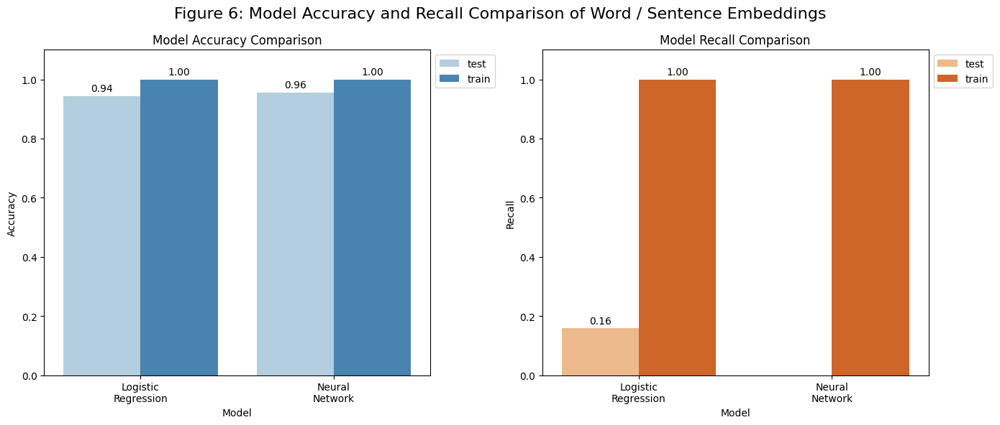

In [975]:
# Ensure that the 'Accuracy' and 'Recall' columns are numeric
df_results_A['Accuracy'] = pd.to_numeric(df_results_A['Accuracy'], errors='coerce')
df_results_A['Recall'] = pd.to_numeric(df_results_A['Recall'], errors='coerce')

# Reset the index to avoid any indexing issues
df_results_A = df_results_A.reset_index(drop=True)

# Create the figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Model Accuracy Comparison
sns.barplot(ax=axes[0], x='Model', y='Accuracy', hue='Train/Test', data=df_results_A, order=model_order, palette='Blues')
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')
axes[0].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))
axes[0].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[0].set_title('Model Accuracy Comparison')
axes[0].set_ylabel('Accuracy')

# Plot 2: Model Recall Comparison (instead of Precision)
sns.barplot(ax=axes[1], x='Model', y='Recall', hue='Train/Test', data=df_results_A, order=model_order, palette='Oranges')
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')
axes[1].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
axes[1].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[1].set_title('Model Recall Comparison')
axes[1].set_ylabel('Recall')

# Add a main title for the figure
fig.suptitle('Figure 6: Model Accuracy and Recall Comparison of Word / Sentence Embeddings', fontsize=16)

# Adjust spacing to avoid overlap
plt.tight_layout()
plt.show()


### 6.2.2. Table for Bag of Words (recall)

In [976]:
# Models
models_B = {"regression": reg2, "neural_network": clf_150_neurons_classification2}

# Datasets
datasets_B = {"test": (X_test2, y_test2), "train": (X_train2, y_train2)}

# Metrics storage
metrics_B = {"Accuracy": {}, "Recall": {}}  # Change Precision to Recall

# Calculate metrics
for model_name, model in models_B.items():
    for dataset_name, (X, y) in datasets_B.items():
        y_pred = model.predict(X)
        # Accuracy
        acc = accuracy_score(y, y_pred)
        metrics_B["Accuracy"][f"{dataset_name}_{model_name}_B"] = acc
        # Recall (instead of Precision)
        rec = recall_score(y, y_pred, average='binary')  # Use recall_score instead of precision_score
        metrics_B["Recall"][f"{dataset_name}_{model_name}_B"] = rec

# Formatted model names
model_name_map = {
    "regression": "Logistic Regression", "neural_network": "Neural Network"}

# Create the DataFrame
data_results_B = {'Train/Test': [], 'Model': [], 'Accuracy': [], 'Recall': []}  # Replace Precision with Recall
for model_key, model_name in model_name_map.items():
    for dataset_name in datasets_B.keys():
        acc_key = f"{dataset_name}_{model_key}_B"
        rec_key = f"{dataset_name}_{model_key}_B"  # Use recall_key instead of precision_key
        data_results_B['Train/Test'].append(dataset_name)
        data_results_B['Model'].append(model_name)
        data_results_B['Accuracy'].append(metrics_B["Accuracy"][acc_key])
        data_results_B['Recall'].append(metrics_B["Recall"][rec_key])  # Store recall here

df_results_B = pd.DataFrame(data_results_B)

# Ensure consistent order for 'Model' column
model_order = ['Logistic Regression', 'Neural Network']
df_results_B['Model'] = pd.Categorical(df_results_B['Model'], categories=model_order, ordered=True)

# Pivot table for Accuracy
df_pivot_B = df_results_B.pivot(index='Model', columns='Train/Test', values='Accuracy')
df_pivot_B['Accuracy Difference (Train - Test)'] = df_pivot_B['train'] - df_pivot_B['test']

# Pivot table for Recall (instead of Precision)
df_pivot_recall_B = df_results_B.pivot(index='Model', columns='Train/Test', values='Recall')  # Replace 'Precision' with 'Recall'
df_pivot_recall_B['Recall Difference (Train - Test)'] = df_pivot_recall_B['train'] - df_pivot_recall_B['test']

# Display both tables
print("Accuracy Table:")
print(df_pivot_B)

print("\nRecall Table:")  # Display recall table instead of precision table
print(df_pivot_recall_B)



Accuracy Table:
Train/Test               test  train  Accuracy Difference (Train - Test)
Model                                                                   
Logistic Regression  0.966814    1.0                            0.033186
Neural Network       0.966814    1.0                            0.033186

Recall Table:
Train/Test           test  train  Recall Difference (Train - Test)
Model                                                             
Logistic Regression   0.0    1.0                               1.0
Neural Network        0.0    1.0                               1.0


<ipython-input-977-56300320a641>:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])
<ipython-input-977-56300320a641>:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])


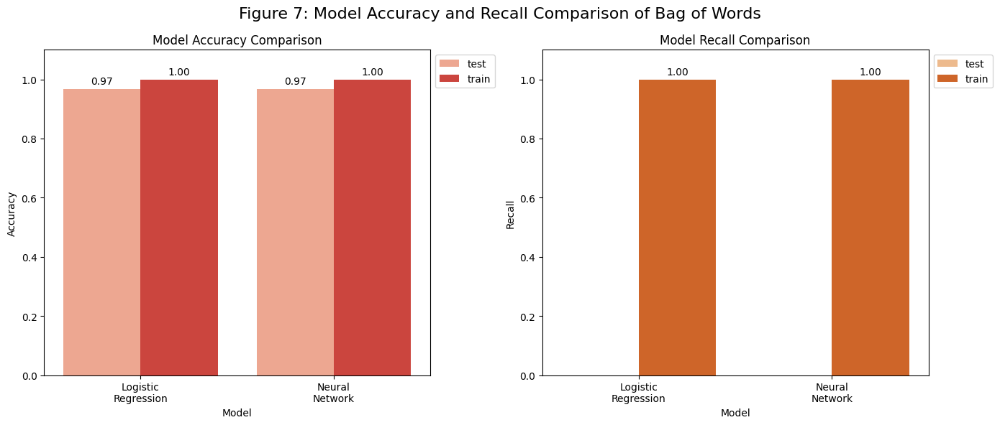

In [977]:
# Create the figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Model Accuracy Comparison (instead of Accuracy)
sns.barplot(ax=axes[0], x='Model', y='Accuracy', hue='Train/Test', data=df_results_B, order=model_order, palette='Reds')
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')
axes[0].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))
axes[0].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[0].set_title('Model Accuracy Comparison')
axes[0].set_ylabel('Accuracy')

# Plot 2: Model Recall Comparison
sns.barplot(ax=axes[1], x='Model', y='Recall', hue='Train/Test', data=df_results_B, order=model_order, palette='Oranges')
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')
axes[1].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
axes[1].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[1].set_title('Model Recall Comparison')
axes[1].set_ylabel('Recall')

# Add a main title for the figure
fig.suptitle('Figure 7: Model Accuracy and Recall Comparison of Bag of Words', fontsize=16)

# Adjust spacing to avoid overlap
plt.tight_layout()
plt.show()


# 7. ADJUSTED MODELS

## 7.1. Adjusted Models for Word / Sentence Embeddings

We can see that the error of test data when calculating recall is much greater than 0 and train data error, so we have a variance problem for both the logistic regression and the neural network.

We will then reduce the number of features for the neural network and add regularization for logistic regression.

### 7.1.1. Adjusted logistic regression

In [978]:
# Instantiate the model with L1 regularization (Lasso)
lasso_model = LogisticRegression(penalty='l1', solver='liblinear')

# Search for the best hyperparameters for regularization (parameter C)
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}  # Adjust regularization strength
grid_search = GridSearchCV(lasso_model, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

# Best model found
best_lasso_model = grid_search.best_estimator_

# Evaluate on the test data
y_pred = best_lasso_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

# Results
print("Best regularization parameter C:", grid_search.best_params_)

Best regularization parameter C: {'C': 0.01}


In [979]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=['No Divorce', 'Divorce'], columns=['Predicted no divorce', 'Predicted divorce'])
print("Confusion Matrix:")
print(cm_df)

Confusion Matrix:
            Predicted no divorce  Predicted divorce
No Divorce                   433                  0
Divorce                       19                  0


In [980]:
print("Accuracy on the training data:", accuracy)

Accuracy on the training data: 0.9579646017699115


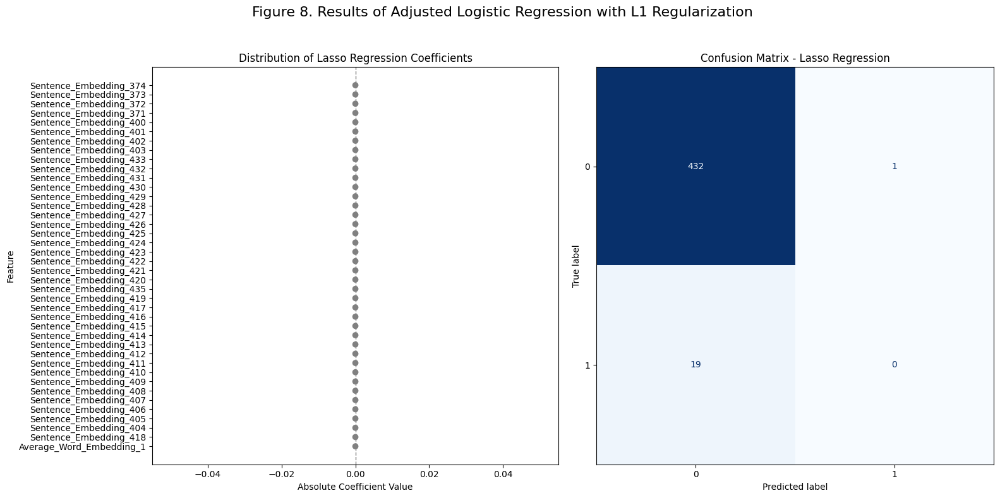

In [981]:
# If X_train is a numpy array, manually provide feature names
feature_names = X_train.columns if hasattr(X_train, 'columns') else [f'Feature {i}' for i in range(X_train.shape[1])]

# Extract coefficients from the best Lasso model
lasso_coefficients = pd.Series(best_lasso_model.coef_.flatten(), index=feature_names)

# Create the figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Add a global title to the panel
fig.suptitle("Figure 8. Results of Adjusted Logistic Regression with L1 Regularization", fontsize=16)

# 1st plot: Distribution of coefficients
plot_sorted_coefficients(lasso_coefficients, axes[0], threshold=1e-08)
axes[0].set_title("Distribution of Lasso Regression Coefficients")

# 2nd plot: Confusion Matrix
# Assuming cm2 is the confusion matrix calculated previously
# cm2 = confusion_matrix(y_test, y_pred)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2)
disp2.plot(cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title("Confusion Matrix - Lasso Regression")

# Adjust spacing to leave space for the global title
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Display the combined figure
plt.show()


### 7.1.2. Adjusted Neural Network

In [982]:
# Neural Network Model with Variance Reduction
clf_reduced_variance = MLPClassifier(
    hidden_layer_sizes=(50, 25),  # Reduced number of neurons
    activation='relu',  # ReLU activation function
    solver='adam',  # Adam optimizer
    max_iter=1000,  # Maximum number of iterations
    alpha=0.1,  # Increased regularization
    tol=1e-4,  # Higher tolerance
    batch_size=100,  # Smaller batch size to simulate dropout
    random_state=666,  # Seed for reproducibility
    early_stopping=True,  # Enable early stopping
    validation_fraction=0.2,  # Fraction of validation data for early stopping
    verbose=True  # Display progress
)

# Train the model on the training data
clf_reduced_variance.fit(X_train, y_train)

# Predict the labels on the test set
y_pred = clf_reduced_variance.predict(X_test)

Iteration 1, loss = 0.61704468
Validation score: 0.969613
Iteration 2, loss = 0.20825424
Validation score: 0.969613
Iteration 3, loss = 0.17883565
Validation score: 0.969613
Iteration 4, loss = 0.14949966
Validation score: 0.969613
Iteration 5, loss = 0.12951461
Validation score: 0.969613
Iteration 6, loss = 0.11594713
Validation score: 0.969613
Iteration 7, loss = 0.10508734
Validation score: 0.969613
Iteration 8, loss = 0.09708572
Validation score: 0.969613
Iteration 9, loss = 0.09124822
Validation score: 0.969613
Iteration 10, loss = 0.08541129
Validation score: 0.969613
Iteration 11, loss = 0.08126074
Validation score: 0.969613
Iteration 12, loss = 0.07735929
Validation score: 0.969613
Validation score did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.


In [983]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=['Divorce', 'No Divorce'], columns=['Predicted Divrorce', 'Predicted No Divorce'])
print("Confusion Matrix:")
print(cm_df)

Confusion Matrix:
            Predicted Divrorce  Predicted No Divorce
Divorce                    432                     1
No Divorce                  19                     0


In [984]:
accuracy_score(y_test, y_pred)

0.9557522123893806

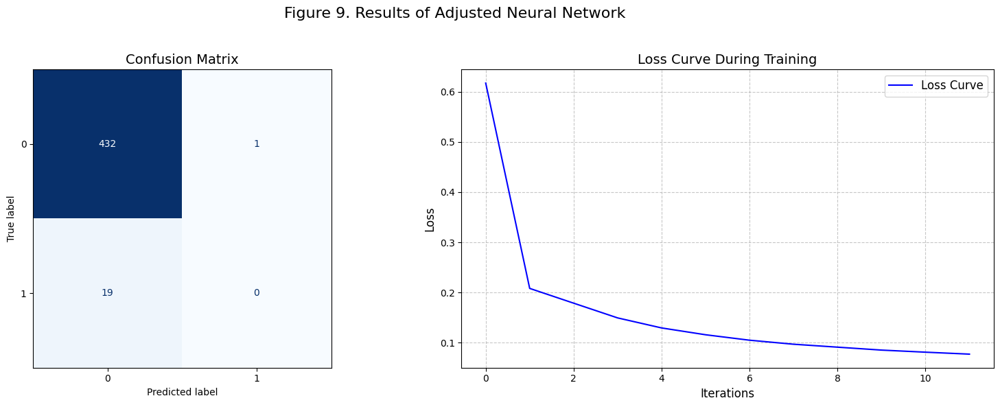

In [985]:
# Create a figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Add a global title to the panel
fig.suptitle("Figure 9. Results of Adjusted Neural Network", fontsize=16)

# First plot: Confusion Matrix
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2)
disp2.plot(cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix", fontsize=14)

# Second plot: Loss Curve
axes[1].plot(clf_reduced_variance.loss_curve_, label="Loss Curve", color="blue")
axes[1].set_title("Loss Curve During Training", fontsize=14)
axes[1].set_xlabel("Iterations", fontsize=12)
axes[1].set_ylabel("Loss", fontsize=12)
axes[1].grid(True, linestyle="--", alpha=0.7)
axes[1].legend(fontsize=12)

# Adjust spacing between the plots
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for the global title

# Display the combined figure
plt.show()


## 7.2. Adjusted Models for Bag of Words

### 7.2.1. Ajusted Logistic Regression

In [986]:
# Instantiate the logistic regression model with L1 regularization (Lasso)
lasso_model = LogisticRegression(penalty='l1', solver='liblinear', max_iter=10000)

# Hyperparameter grid for the regularization parameter C
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}  # Adjusting the strength of the regularization

# Perform GridSearchCV to find the best regularization strength
grid_search = GridSearchCV(lasso_model, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train2, y_train2)

# Best model found from grid search
best_lasso_model2 = grid_search.best_estimator_

# Evaluate the best model on the test set
y_pred2 = best_lasso_model2.predict(X_test2)  # Predict on the test set
accuracy = accuracy_score(y_test2, y_pred2)  # Calculate accuracy

# Print the results
print("Best regularization parameter C:", grid_search.best_params_)


Best regularization parameter C: {'C': 0.01}


In [987]:
# Confusion matrix
cmBG = confusion_matrix(y_test2, y_pred2)
cmBG_df = pd.DataFrame(cmBG, index=['No Divorce', 'Divorce'], columns=['Predicted no divorce', 'Predicted divorce'])
print("Confusion Matrix:")
print(cmBG_df)

Confusion Matrix:
            Predicted no divorce  Predicted divorce
No Divorce                   437                  0
Divorce                       15                  0


In [988]:
print("Accuracy on the training data:", accuracy)

Accuracy on the training data: 0.9668141592920354


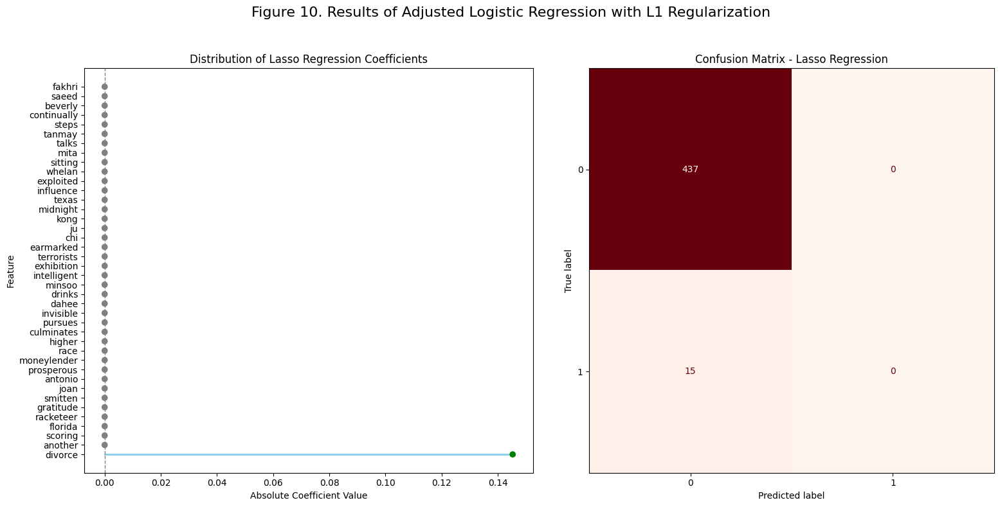

In [989]:
# If X_train2 is a numpy array, manually provide feature names
feature_names = X_train2.columns if hasattr(X_train2, 'columns') else [f'Feature {i}' for i in range(X_train2.shape[1])]

# Extract coefficients from the best Lasso model
lasso_coefficients2 = pd.Series(best_lasso_model2.coef_.flatten(), index=feature_names)

# Create the figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Add a global title to the panel
fig.suptitle("Figure 10. Results of Adjusted Logistic Regression with L1 Regularization", fontsize=16)

# 1st plot: Distribution of coefficients
plot_sorted_coefficients(lasso_coefficients2, axes[0], threshold=1e-08)
axes[0].set_title("Distribution of Lasso Regression Coefficients")

# 2nd plot: Confusion Matrix
# Assuming cm2 is the confusion matrix calculated previously
# cm2 = confusion_matrix(y_test, y_pred)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cmBG)
disp2.plot(cmap='Reds', ax=axes[1], colorbar=False)
axes[1].set_title("Confusion Matrix - Lasso Regression")

# Adjust spacing to leave space for the global title
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Display the combined figure
plt.show()


### 7.2.2. Adjusted Neural Network

In [990]:
# Neural Network Model with Variance Reduction (adapted to the new dataset)
clf_reduced_variance2 = MLPClassifier(
    hidden_layer_sizes=(50, 25),  # Reduced number of neurons (50 and 25)
    activation='relu',  # ReLU activation function
    solver='adam',  # Adam optimizer
    max_iter=1000,  # Maximum number of iterations
    alpha=0.1,  # Increased regularization to prevent overfitting
    tol=1e-4,  # Higher tolerance for stopping criteria
    batch_size=100,  # Smaller batch size to simulate dropout
    random_state=666,  # Random seed for reproducibility
    early_stopping=True,  # Enable early stopping to avoid overfitting
    validation_fraction=0.2,  # Fraction of validation data for early stopping
    verbose=True  # Display progress during training
)

# Train the model on the training data (adapted to the new dataset)
clf_reduced_variance2.fit(X_train2, y_train2)

# Predict the labels on the test set (using the new dataset)
y_pred2 = clf_reduced_variance2.predict(X_test2)

Iteration 1, loss = 1.39667240
Validation score: 0.616022
Iteration 2, loss = 0.24304374
Validation score: 0.668508
Iteration 3, loss = 0.16183390
Validation score: 0.704420
Iteration 4, loss = 0.13326518
Validation score: 0.704420
Iteration 5, loss = 0.11690386
Validation score: 0.701657
Iteration 6, loss = 0.10792346
Validation score: 0.701657
Iteration 7, loss = 0.10055180
Validation score: 0.698895
Iteration 8, loss = 0.09467891
Validation score: 0.696133
Iteration 9, loss = 0.09013211
Validation score: 0.693370
Iteration 10, loss = 0.08619609
Validation score: 0.696133
Iteration 11, loss = 0.08261454
Validation score: 0.701657
Iteration 12, loss = 0.07943306
Validation score: 0.704420
Iteration 13, loss = 0.07654731
Validation score: 0.704420
Iteration 14, loss = 0.07393425
Validation score: 0.701657
Validation score did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.


In [991]:
# Confusion matrix
cmBG2 = confusion_matrix(y_test2, y_pred2)
cmBG2_df = pd.DataFrame(cmBG2, index=['Divorce', 'No Divorce'], columns=['Predicted Divrorce', 'Predicted No Divorce'])
print("Confusion Matrix:")
print(cmBG2_df)

Confusion Matrix:
            Predicted Divrorce  Predicted No Divorce
Divorce                    312                   125
No Divorce                  10                     5


In [992]:
accuracy_score(y_test2, y_pred2)

0.7013274336283186

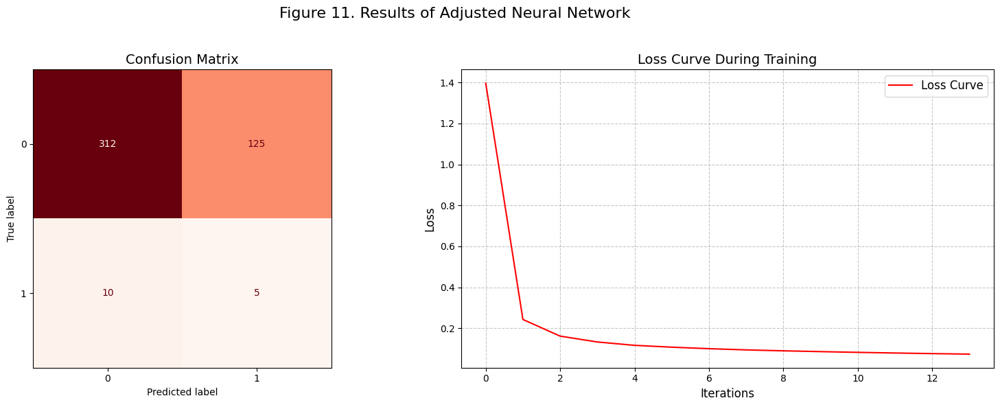

In [993]:
# Assuming clf_reduced_variance_C3 has been trained and y_pred2 is generated
# Generate confusion matrix for the predictions
cm2 = confusion_matrix(y_test2, y_pred2)

# Create a figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Add a global title to the panel
fig.suptitle("Figure 11. Results of Adjusted Neural Network", fontsize=16)

# First plot: Confusion Matrix
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2)
disp2.plot(cmap='Reds', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix", fontsize=14)

# Second plot: Loss Curve
axes[1].plot(clf_reduced_variance2.loss_curve_, label="Loss Curve", color="red")
axes[1].set_title("Loss Curve During Training", fontsize=14)
axes[1].set_xlabel("Iterations", fontsize=12)
axes[1].set_ylabel("Loss", fontsize=12)
axes[1].grid(True, linestyle="--", alpha=0.7)
axes[1].legend(fontsize=12)

# Adjust spacing between the plots
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for the global title

# Display the combined figure
plt.show()


# 8. DIAGNOSTIC OF ADJUSTED MODELS

## 8.1. Diagnostic of the adjusted models for the Word / Sentence Embeddings

### 8.1.1. Diagnostic of the logistic regression with regularization (recall)

In [994]:
# Models
models_C2 = {
    "lasso_logistic_regression": best_lasso_model  # Adding only the Lasso model
}

# Datasets
datasets_C2 = {
    "test": (X_test, y_test),
    "train": (X_train, y_train)
}

# Initialize dictionaries for storing metrics
accuracies_C2 = {}
recalls_C2 = {}

# Calculate metrics for each model and dataset
for model_name, model in models_C2.items():
    for dataset_name, (X, y) in datasets_C2.items():
        # Predict using the model
        y_pred = model.predict(X)

        # Calculate accuracy
        acc_key = f"acc_{dataset_name}_{model_name}_C2"
        accuracies_C2[acc_key] = accuracy_score(y, y_pred)

        # Calculate recall
        recall_key = f"recall_{dataset_name}_{model_name}_C2"  # Fix the key pattern here
        recalls_C2[recall_key] = recall_score(y, y_pred, average='binary')  # Use 'binary' for binary classification

# Map model keys to formatted names for the DataFrame
model_name_map = {
    "lasso_logistic_regression": "Lasso Logistic Regression"
}

# Create a structured dictionary for results
data_results_C2 = {'Train/Test': [], 'Model': [], 'Accuracy': [], 'Recall': []}
for model_key, model_name in model_name_map.items():
    for dataset_name in datasets_C2.keys():
        acc_key = f"acc_{dataset_name}_{model_key}_C2"
        recall_key = f"recall_{dataset_name}_{model_key}_C2"  # Match the fixed key pattern

        # Retrieve values from the populated dictionaries
        data_results_C2['Train/Test'].append(dataset_name)
        data_results_C2['Model'].append(model_name)
        data_results_C2['Accuracy'].append(accuracies_C2[acc_key])
        data_results_C2['Recall'].append(recalls_C2[recall_key])

# Create the DataFrame
df_results_C2 = pd.DataFrame(data_results_C2)

# Ensure consistent order for 'Model' column
model_order = ['Lasso Logistic Regression']
df_results_C2['Model'] = pd.Categorical(df_results_C2['Model'], categories=model_order, ordered=True)

# Pivot table for Accuracy
df_pivot_C2_accuracy = df_results_C2.pivot(index='Model', columns='Train/Test', values='Accuracy')
df_pivot_C2_accuracy['Accuracy Difference (Train - Test)'] = (
    df_pivot_C2_accuracy['train'] - df_pivot_C2_accuracy['test']
)

# Pivot table for Recall
df_pivot_C2_recall = df_results_C2.pivot(index='Model', columns='Train/Test', values='Recall')
df_pivot_C2_recall['Recall Difference (Train - Test)'] = (
    df_pivot_C2_recall['train'] - df_pivot_C2_recall['test']
)

# Display both tables using tabulate
print("Accuracy Table:")
print(tabulate(df_pivot_C2_accuracy, headers='keys', tablefmt='fancy_grid', showindex=True))

print("\nRecall Table:")
print(tabulate(df_pivot_C2_recall, headers='keys', tablefmt='fancy_grid', showindex=True))




Accuracy Table:
╒═══════════════════════════╤══════════╤══════════╤══════════════════════════════════════╕
│ Model                     │     test │    train │   Accuracy Difference (Train - Test) │
╞═══════════════════════════╪══════════╪══════════╪══════════════════════════════════════╡
│ Lasso Logistic Regression │ 0.957965 │ 0.968473 │                            0.0105088 │
╘═══════════════════════════╧══════════╧══════════╧══════════════════════════════════════╛

Recall Table:
╒═══════════════════════════╤════════╤═════════╤════════════════════════════════════╕
│ Model                     │   test │   train │   Recall Difference (Train - Test) │
╞═══════════════════════════╪════════╪═════════╪════════════════════════════════════╡
│ Lasso Logistic Regression │      0 │       0 │                                  0 │
╘═══════════════════════════╧════════╧═════════╧════════════════════════════════════╛


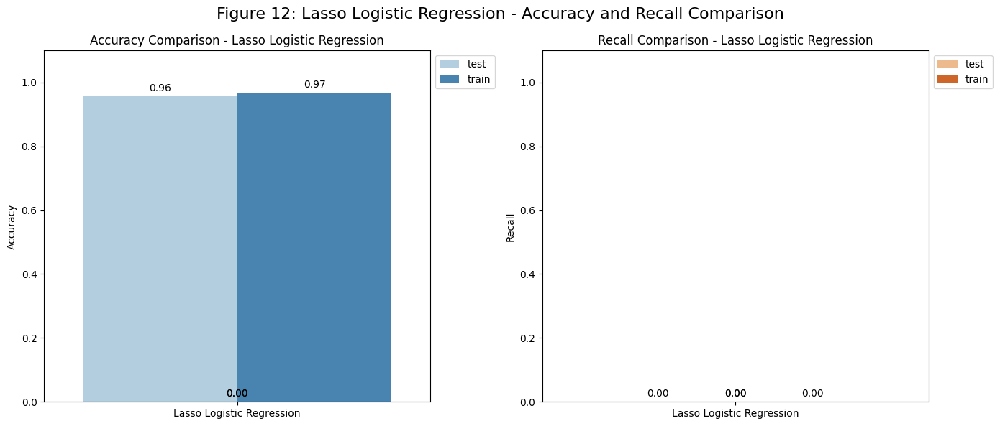

In [995]:
# Create the figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define model order for Lasso Logistic Regression only
model_order = ['Lasso Logistic Regression']

# Plot 1: Accuracy Comparison for Lasso Logistic Regression
sns.barplot(
    ax=axes[0],
    x='Model',
    y='Accuracy',
    hue='Train/Test',
    data=df_results_C2,
    order=model_order,
    palette='Blues'
)

# Add annotations to the bars for accuracy
for p in axes[0].patches:
    height = p.get_height()
    if not pd.isna(height):  # Avoid issues with NaN values
        axes[0].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[0].set_title('Accuracy Comparison - Lasso Logistic Regression')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Plot 2: Recall Comparison for Lasso Logistic Regression
sns.barplot(
    ax=axes[1],
    x='Model',
    y='Recall',
    hue='Train/Test',
    data=df_results_C2,
    order=model_order,
    palette='Oranges'
)

# Add annotations to the bars for recall
for p in axes[1].patches:
    height = p.get_height()
    if not pd.isna(height):  # Avoid issues with NaN values
        axes[1].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[1].set_title('Recall Comparison - Lasso Logistic Regression')
axes[1].set_ylabel('Recall')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Add a main title for the figure
fig.suptitle('Figure 12: Lasso Logistic Regression - Accuracy and Recall Comparison', fontsize=16)

# Adjust spacing to avoid overlap
plt.tight_layout()
plt.show()


### 8.1.2. Diagnostic of the adjusted neural network (recall)

In [996]:
# Models: Replacing the lasso model with the neural network model
models_D2 = {
    "neural_network_reduced_variance": clf_reduced_variance  # Using Neural Network with reduced variance
}

# Datasets
datasets_D2 = {
    "test": (X_test, y_test),
    "train": (X_train, y_train)
}

# Initialize dictionaries for storing metrics
accuracies_D2 = {}
recalls_D2 = {}

# Calculate metrics for each model and dataset
for model_name, model in models_D2.items():
    for dataset_name, (X, y) in datasets_D2.items():
        # Predict using the model
        y_pred = model.predict(X)

        # Calculate accuracy
        acc_key = f"acc_{dataset_name}_{model_name}_D2"
        accuracies_D2[acc_key] = accuracy_score(y, y_pred)

        # Calculate recall
        recall_key = f"recall_{dataset_name}_{model_name}_D2"
        recalls_D2[recall_key] = recall_score(y, y_pred, average='binary')  # Use 'binary' for binary classification

# Map model keys to formatted names for the DataFrame
model_name_map = {
    "neural_network_reduced_variance": "Neural Network with Reduced Variance"
}

# Create a structured dictionary for results
data_results_D2 = {'Train/Test': [], 'Model': [], 'Accuracy': [], 'Recall': []}
for model_key, model_name in model_name_map.items():
    for dataset_name in datasets_D2.keys():
        acc_key = f"acc_{dataset_name}_{model_key}_D2"
        recall_key = f"recall_{dataset_name}_{model_key}_D2"

        # Retrieve values from the populated dictionaries
        data_results_D2['Train/Test'].append(dataset_name)
        data_results_D2['Model'].append(model_name)
        data_results_D2['Accuracy'].append(accuracies_D2[acc_key])
        data_results_D2['Recall'].append(recalls_D2[recall_key])

# Create the DataFrame
df_results_D2 = pd.DataFrame(data_results_D2)

# Ensure consistent order for 'Model' column
model_order = ['Neural Network with Reduced Variance']
df_results_D2['Model'] = pd.Categorical(df_results_D2['Model'], categories=model_order, ordered=True)

# Pivot table for Accuracy
df_pivot_D2_accuracy = df_results_D2.pivot(index='Model', columns='Train/Test', values='Accuracy')
df_pivot_D2_accuracy['Accuracy Difference (Train - Test)'] = df_pivot_D2_accuracy['train'] - df_pivot_D2_accuracy['test']

# Pivot table for Recall
df_pivot_D2_recall = df_results_D2.pivot(index='Model', columns='Train/Test', values='Recall')
df_pivot_D2_recall['Recall Difference (Train - Test)'] = df_pivot_D2_recall['train'] - df_pivot_D2_recall['test']

# Display both tables using tabulate
print("Accuracy Table:")
print(tabulate(df_pivot_D2_accuracy, headers='keys', tablefmt='fancy_grid', showindex=True))

print("\nRecall Table:")
print(tabulate(df_pivot_D2_recall, headers='keys', tablefmt='fancy_grid', showindex=True))


Accuracy Table:
╒══════════════════════════════════════╤══════════╤══════════╤══════════════════════════════════════╕
│ Model                                │     test │    train │   Accuracy Difference (Train - Test) │
╞══════════════════════════════════════╪══════════╪══════════╪══════════════════════════════════════╡
│ Neural Network with Reduced Variance │ 0.955752 │ 0.968473 │                            0.0127212 │
╘══════════════════════════════════════╧══════════╧══════════╧══════════════════════════════════════╛

Recall Table:
╒══════════════════════════════════════╤════════╤═════════╤════════════════════════════════════╕
│ Model                                │   test │   train │   Recall Difference (Train - Test) │
╞══════════════════════════════════════╪════════╪═════════╪════════════════════════════════════╡
│ Neural Network with Reduced Variance │      0 │       0 │                                  0 │
╘══════════════════════════════════════╧════════╧═════════╧════════════

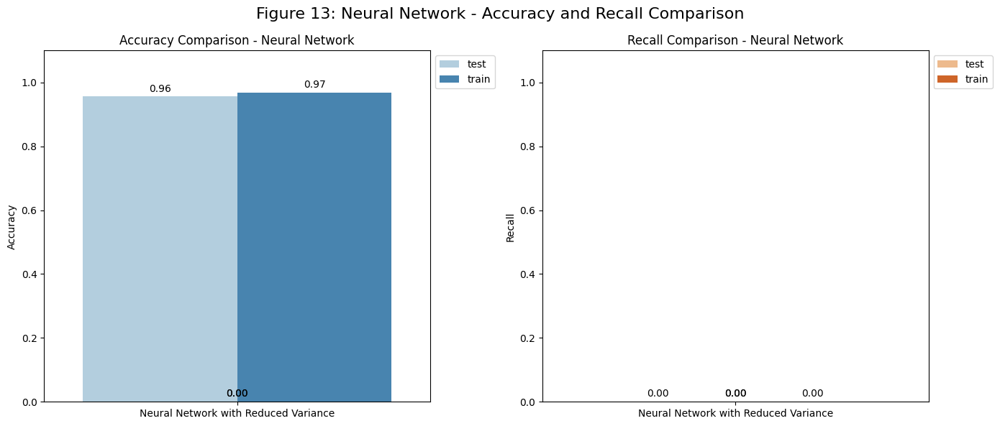

In [997]:
# Create the figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define model order for the specific model (e.g., "Neural Network" or any other)
model_order = ['Neural Network with Reduced Variance']  # Change the model name as needed

# Plot 1: Accuracy Comparison for the chosen model (e.g., Neural Network)
sns.barplot(
    ax=axes[0],
    x='Model',
    y='Accuracy',
    hue='Train/Test',
    data=df_results_D2,  # Use the relevant DataFrame for the new model
    order=model_order,
    palette='Blues'
)

# Add annotations to the bars for accuracy
for p in axes[0].patches:
    height = p.get_height()
    if not pd.isna(height):  # Avoid issues with NaN values
        axes[0].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[0].set_title('Accuracy Comparison - Neural Network')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Plot 2: Recall Comparison for the chosen model (e.g., Neural Network)
sns.barplot(
    ax=axes[1],
    x='Model',
    y='Recall',  # Using Recall instead of Precision
    hue='Train/Test',
    data=df_results_D2,  # Use the relevant DataFrame for the new model
    order=model_order,
    palette='Oranges'
)

# Add annotations to the bars for recall
for p in axes[1].patches:
    height = p.get_height()
    if not pd.isna(height):  # Avoid issues with NaN values
        axes[1].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[1].set_title('Recall Comparison - Neural Network')
axes[1].set_ylabel('Recall')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Add a main title for the figure
fig.suptitle('Figure 13: Neural Network - Accuracy and Recall Comparison', fontsize=16)  # Replace 'X' with the figure number

# Adjust spacing to avoid overlap
plt.tight_layout()
plt.show()


## 8.2. Diagnostic of the adjusted models for the Bag of Words

### 8.2.1. Diagnostic of the logistic regression with regularization (recall)

In [998]:
# Models
models_C3 = {
    "lasso_logistic_regression": best_lasso_model2  # Adding the newly found best Lasso model
}

# Datasets
datasets_C3 = {
    "test": (X_test2, y_test2),  # Updated to use X_test2, y_test2
    "train": (X_train2, y_train2)  # Updated to use X_train2, y_train2
}

# Initialize dictionaries for storing metrics
accuracies_C3 = {}
recalls_C3 = {}

# Calculate metrics for each model and dataset
for model_name, model in models_C3.items():
    for dataset_name, (X, y) in datasets_C3.items():
        # Predict using the model
        y_pred = model.predict(X)

        # Calculate accuracy
        acc_key = f"acc_{dataset_name}_{model_name}_C3"
        accuracies_C3[acc_key] = accuracy_score(y, y_pred)

        # Calculate recall
        recall_key = f"recall_{dataset_name}_{model_name}_C3"
        recalls_C3[recall_key] = recall_score(y, y_pred, average='binary')  # Use 'binary' for binary classification

# Map model keys to formatted names for the DataFrame
model_name_map = {
    "lasso_logistic_regression": "Lasso Logistic Regression"
}

# Create a structured dictionary for results
data_results_C3 = {'Train/Test': [], 'Model': [], 'Accuracy': [], 'Recall': []}
for model_key, model_name in model_name_map.items():
    for dataset_name in datasets_C3.keys():
        acc_key = f"acc_{dataset_name}_{model_key}_C3"
        recall_key = f"recall_{dataset_name}_{model_key}_C3"

        # Retrieve values from the populated dictionaries
        data_results_C3['Train/Test'].append(dataset_name)
        data_results_C3['Model'].append(model_name)
        data_results_C3['Accuracy'].append(accuracies_C3[acc_key])
        data_results_C3['Recall'].append(recalls_C3[recall_key])

# Create the DataFrame
df_results_C3 = pd.DataFrame(data_results_C3)

# Ensure consistent order for 'Model' column
model_order = ['Lasso Logistic Regression']
df_results_C3['Model'] = pd.Categorical(df_results_C3['Model'], categories=model_order, ordered=True)

# Pivot table for Accuracy
df_pivot_C3_accuracy = df_results_C3.pivot(index='Model', columns='Train/Test', values='Accuracy')
df_pivot_C3_accuracy['Accuracy Difference (Train - Test)'] = (
    df_pivot_C3_accuracy['train'] - df_pivot_C3_accuracy['test']
)

# Pivot table for Recall
df_pivot_C3_recall = df_results_C3.pivot(index='Model', columns='Train/Test', values='Recall')
df_pivot_C3_recall['Recall Difference (Train - Test)'] = (
    df_pivot_C3_recall['train'] - df_pivot_C3_recall['test']
)

# Display both tables using tabulate
print("Accuracy Table:")
print(tabulate(df_pivot_C3_accuracy, headers='keys', tablefmt='fancy_grid', showindex=True))

print("\nRecall Table:")
print(tabulate(df_pivot_C3_recall, headers='keys', tablefmt='fancy_grid', showindex=True))



Accuracy Table:
╒═══════════════════════════╤══════════╤══════════╤══════════════════════════════════════╕
│ Model                     │     test │    train │   Accuracy Difference (Train - Test) │
╞═══════════════════════════╪══════════╪══════════╪══════════════════════════════════════╡
│ Lasso Logistic Regression │ 0.966814 │ 0.966777 │                         -3.67507e-05 │
╘═══════════════════════════╧══════════╧══════════╧══════════════════════════════════════╛

Recall Table:
╒═══════════════════════════╤════════╤═══════════╤════════════════════════════════════╕
│ Model                     │   test │     train │   Recall Difference (Train - Test) │
╞═══════════════════════════╪════════╪═══════════╪════════════════════════════════════╡
│ Lasso Logistic Regression │      0 │ 0.0163934 │                          0.0163934 │
╘═══════════════════════════╧════════╧═══════════╧════════════════════════════════════╛


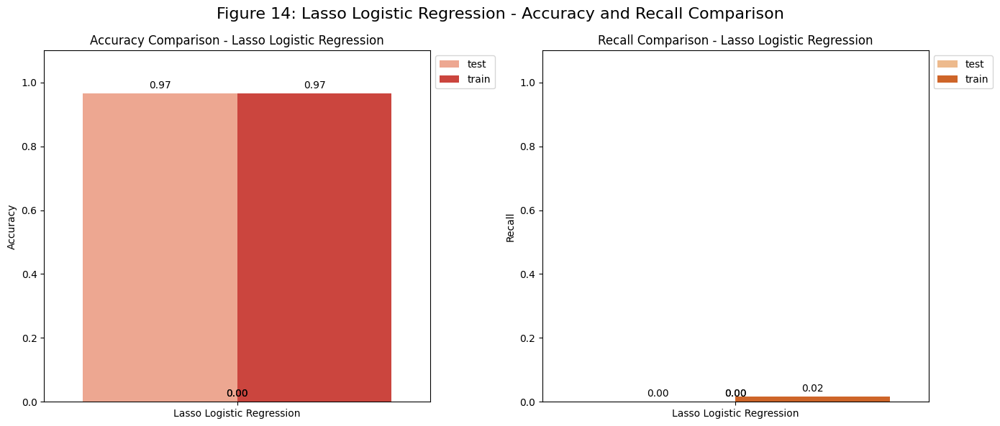

In [999]:
# Create the figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define model order for Lasso Logistic Regression only
model_order = ['Lasso Logistic Regression']

# Plot 1: Accuracy Comparison for Lasso Logistic Regression
sns.barplot(
    ax=axes[0],
    x='Model',
    y='Accuracy',
    hue='Train/Test',
    data=df_results_C3,  # Change to df_results_C3
    order=model_order,
    palette='Reds'
)

# Add annotations to the bars for accuracy
for p in axes[0].patches:
    height = p.get_height()
    if not pd.isna(height):  # Avoid issues with NaN values
        axes[0].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[0].set_title('Accuracy Comparison - Lasso Logistic Regression')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Plot 2: Recall Comparison for Lasso Logistic Regression
sns.barplot(
    ax=axes[1],
    x='Model',
    y='Recall',
    hue='Train/Test',
    data=df_results_C3,  # Change to df_results_C3
    order=model_order,
    palette='Oranges'
)

# Add annotations to the bars for recall
for p in axes[1].patches:
    height = p.get_height()
    if not pd.isna(height):  # Avoid issues with NaN values
        axes[1].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[1].set_title('Recall Comparison - Lasso Logistic Regression')
axes[1].set_ylabel('Recall')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Add a main title for the figure
fig.suptitle('Figure 14: Lasso Logistic Regression - Accuracy and Recall Comparison', fontsize=16)

# Adjust spacing to avoid overlap
plt.tight_layout()
plt.show()


### 8.2.2. Diagnostic of the Neural Network (recall)

In [1000]:
# Models
models_C4 = {
    "neural_network": clf_reduced_variance2  # Neural Network with Variance Reduction model
}

# Datasets
datasets_C4 = {
    "test": (X_test2, y_test2),  # Use updated test dataset
    "train": (X_train2, y_train2)  # Use updated train dataset
}

# Initialize dictionaries for storing metrics
accuracies_C4 = {}
recalls_C4 = {}

# Calculate metrics for each model and dataset
for model_name, model in models_C4.items():
    for dataset_name, (X, y) in datasets_C4.items():
        # Predict using the model
        y_pred = model.predict(X)

        # Calculate accuracy
        acc_key = f"acc_{dataset_name}_{model_name}_C4"
        accuracies_C4[acc_key] = accuracy_score(y, y_pred)

        # Calculate recall
        recall_key = f"recall_{dataset_name}_{model_name}_C4"
        recalls_C4[recall_key] = recall_score(y, y_pred, average='binary')  # Use 'binary' for binary classification

# Map model keys to formatted names for the DataFrame
model_name_map_C4 = {
    "neural_network": "Neural Network (Variance Reduction)"
}

# Create a structured dictionary for results
data_results_C4 = {'Train/Test': [], 'Model': [], 'Accuracy': [], 'Recall': []}
for model_key, model_name in model_name_map_C4.items():
    for dataset_name in datasets_C4.keys():
        acc_key = f"acc_{dataset_name}_{model_key}_C4"
        recall_key = f"recall_{dataset_name}_{model_key}_C4"

        # Retrieve values from the populated dictionaries
        data_results_C4['Train/Test'].append(dataset_name)
        data_results_C4['Model'].append(model_name)
        data_results_C4['Accuracy'].append(accuracies_C4[acc_key])
        data_results_C4['Recall'].append(recalls_C4[recall_key])

# Create the DataFrame
df_results_C4 = pd.DataFrame(data_results_C4)

# Ensure consistent order for 'Model' column
model_order_C4 = ['Neural Network (Variance Reduction)']
df_results_C4['Model'] = pd.Categorical(df_results_C4['Model'], categories=model_order_C4, ordered=True)

# Pivot table for Accuracy
df_pivot_C4_accuracy = df_results_C4.pivot(index='Model', columns='Train/Test', values='Accuracy')
df_pivot_C4_accuracy['Accuracy Difference (Train - Test)'] = df_pivot_C4_accuracy['train'] - df_pivot_C4_accuracy['test']

# Pivot table for Recall
df_pivot_C4_recall = df_results_C4.pivot(index='Model', columns='Train/Test', values='Recall')
df_pivot_C4_recall['Recall Difference (Train - Test)'] = df_pivot_C4_recall['train'] - df_pivot_C4_recall['test']

# Display Accuracy Table
print("\nAccuracy Table:")
print(tabulate(df_pivot_C4_accuracy, headers='keys', tablefmt='fancy_grid', showindex=True))

# Display Recall Table
print("\nRecall Table:")
print(tabulate(df_pivot_C4_recall, headers='keys', tablefmt='fancy_grid', showindex=True))




Accuracy Table:
╒═════════════════════════════════════╤══════════╤══════════╤══════════════════════════════════════╕
│ Model                               │     test │    train │   Accuracy Difference (Train - Test) │
╞═════════════════════════════════════╪══════════╪══════════╪══════════════════════════════════════╡
│ Neural Network (Variance Reduction) │ 0.701327 │ 0.927464 │                             0.226137 │
╘═════════════════════════════════════╧══════════╧══════════╧══════════════════════════════════════╛

Recall Table:
╒═════════════════════════════════════╤══════════╤═════════╤════════════════════════════════════╕
│ Model                               │     test │   train │   Recall Difference (Train - Test) │
╞═════════════════════════════════════╪══════════╪═════════╪════════════════════════════════════╡
│ Neural Network (Variance Reduction) │ 0.333333 │ 0.47541 │                           0.142077 │
╘═════════════════════════════════════╧══════════╧═════════╧═══════════

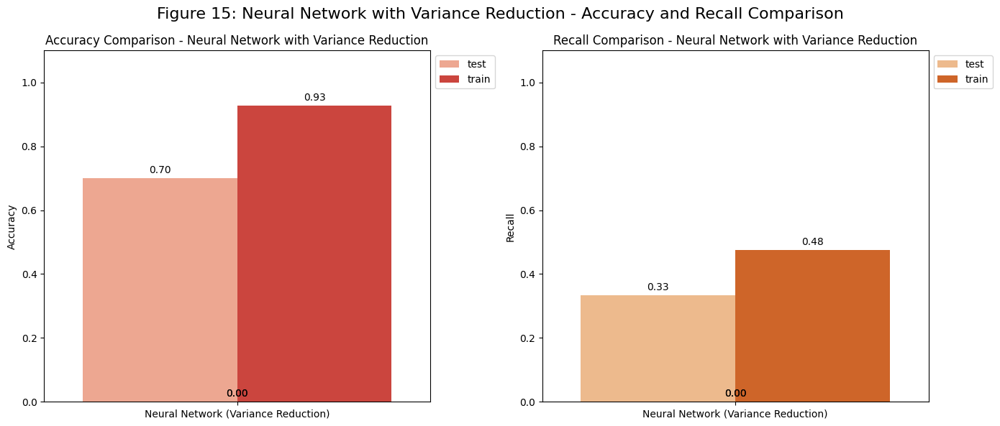

In [1001]:
# Create the figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define model order for Neural Network (Variance Reduction)
model_order = ['Neural Network (Variance Reduction)']

# Plot 1: Accuracy Comparison for Neural Network
sns.barplot(
    ax=axes[0],
    x='Model',
    y='Accuracy',
    hue='Train/Test',
    data=df_results_C4,  # Use df_results_C4 for Neural Network model
    order=model_order,
    palette='Reds'
)

# Add annotations to the bars for accuracy
for p in axes[0].patches:
    height = p.get_height()
    if not pd.isna(height):  # Avoid issues with NaN values
        axes[0].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[0].set_title('Accuracy Comparison - Neural Network with Variance Reduction')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Plot 2: Recall Comparison for Neural Network
sns.barplot(
    ax=axes[1],
    x='Model',
    y='Recall',
    hue='Train/Test',
    data=df_results_C4,  # Use df_results_C4 for Neural Network model
    order=model_order,
    palette='Oranges'
)

# Add annotations to the bars for recall
for p in axes[1].patches:
    height = p.get_height()
    if not pd.isna(height):  # Avoid issues with NaN values
        axes[1].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[1].set_title('Recall Comparison - Neural Network with Variance Reduction')
axes[1].set_ylabel('Recall')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Add a main title for the figure
fig.suptitle('Figure 15: Neural Network with Variance Reduction - Accuracy and Recall Comparison', fontsize=16)

# Adjust spacing to avoid overlap
plt.tight_layout()
plt.show()

# 9. ADJUSTED DATA TRAIN / TEST

## 9.1. Dataset of the Word / Sentence Embeddings

We can see that the error of test data when calculating recall is much greater than 0 and train data error (see Section 6), so we have a variance problem for both the logistic regression and the neural network.

To remedy this, we will change the training dataset by having equal proportions of divorce/ non-divorce. The model will be forced to train itself in order to predict divorces and not just say that no film contains a divorce so as to have high accuracy.

### 9.1.1. Split data into Train / Test

In [1002]:
# Separate the data by the target class (txtDivorce)
y_train_1 = X_train[y_train == 1]
y_train_0 = X_train[y_train == 0]

# Calculate the number of samples needed for each class
num_ones = y_train_1.shape[0]
num_zeros = y_train_0.shape[0]

# Get 50% of the "1"s and "0"s
num_samples = min(num_ones, num_zeros) // 2

# Create the balanced dataset by taking equal numbers of "1"s and "0"s
X_new_train = pd.concat([y_train_1.sample(n=num_samples, random_state=666), y_train_0.sample(n=num_samples, random_state=666)])
y_new_train = pd.concat([y_train[y_train == 1].sample(n=num_samples, random_state=666), y_train[y_train == 0].sample(n=num_samples, random_state=666)])

# Shuffle the resulting dataset to ensure randomness
X_new_train = X_new_train.sample(frac=1, random_state=666)
y_new_train = y_new_train[X_new_train.index]

# Check the size of the resulting dataset
print(f"Number of samples in the new training set: {X_new_train.shape[0]}")
print(f"Number of 1s in y_new_train: {y_new_train.sum()}")
print(f"Number of 0s in y_new_train: {len(y_new_train) - y_new_train.sum()}")


Number of samples in the new training set: 56
Number of 1s in y_new_train: 28.0
Number of 0s in y_new_train: 28.0


In [1003]:
# Get the indices of the data used in X_new_train
used_indices = X_new_train.index

# Create the test sets with the remaining data
X_new_test = X_train.drop(index=used_indices)
y_new_test = y_train.drop(index=used_indices)

# Check the sizes to validate the split
print(f"Number of samples in the new test set: {X_new_test.shape[0]}")
print(f"Number of 1s in y_new_test: {y_new_test.sum()}")
print(f"Number of 0s in y_new_test: {len(y_new_test) - y_new_test.sum()}")


Number of samples in the new test set: 1752
Number of 1s in y_new_test: 29.0
Number of 0s in y_new_test: 1723.0


### 9.1.2. Logistic regression with the new train dataset

In [1004]:
# Performing Logistic Regression
reg = LogisticRegression(max_iter = 10000)
reg.fit(X_new_train, y_new_train)

coef = pd.Series(reg.coef_.flatten(), index = X_new_train.columns)

In [1005]:
# Test the logistic regression
y_new_pred = reg.predict(X_new_test)

In [1006]:
# Confusion matrix
cm3 = confusion_matrix(y_new_test, y_new_pred)
cm3_df = pd.DataFrame(cm3, index=['No Divorce', 'Divorce'], columns=['Predicted no divorce', 'Predicted divorce'])
print("Confusion Matrix:")
print(cm3_df)

Confusion Matrix:
            Predicted no divorce  Predicted divorce
No Divorce                   892                831
Divorce                       12                 17


In [1007]:
accuracy_score(y_new_test, y_new_pred)

0.5188356164383562

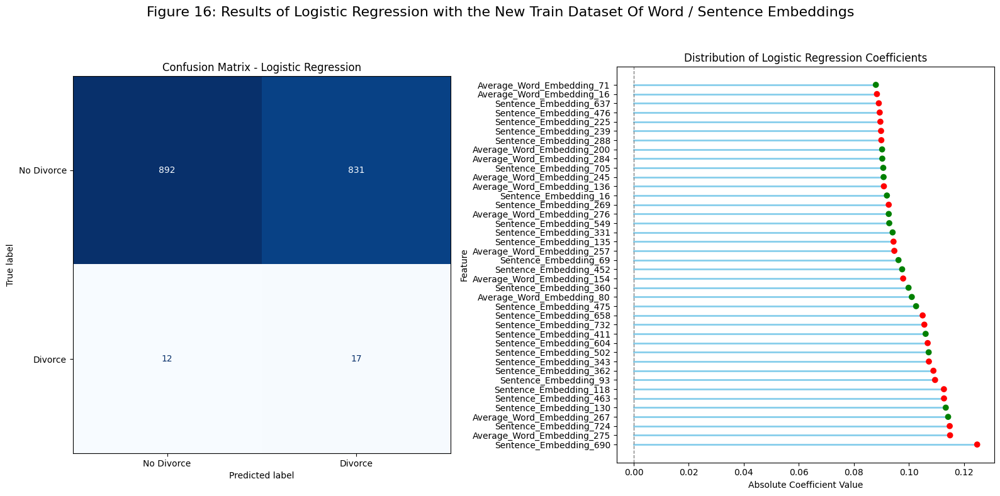

In [1008]:
# If X_new_train is a numpy array, manually provide feature names
feature_names = X_new_train.columns if hasattr(X_new_train, 'columns') else [f'Feature {i}' for i in range(X_new_train.shape[1])]

# Extract coefficients from the logistic regression model
logistic_coefficients = pd.Series(reg.coef_.flatten(), index=feature_names)

# Create the figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Add a global title to the panel
fig.suptitle("Figure 16: Results of Logistic Regression with the New Train Dataset Of Word / Sentence Embeddings", fontsize=16)

# 1st plot: Confusion Matrix
disp3 = ConfusionMatrixDisplay(confusion_matrix=cm3, display_labels=['No Divorce', 'Divorce'])
disp3.plot(cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix - Logistic Regression")

# 2nd plot: Distribution of coefficients
plot_sorted_coefficients(logistic_coefficients, axes[1], threshold=1e-08)
axes[1].set_title("Distribution of Logistic Regression Coefficients")

# Adjust spacing to leave space for the global title
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Display the combined figure
plt.show()


### 9.1.3. Neural Network with the new train dataset

In [1009]:
# Large Neural Network with three hidden layers ([100,50] neurons)
clf_150_neurons_classification = MLPClassifier(
    hidden_layer_sizes=(100, 50),  # Three hidden layers with 100 and 50 neurons respectively
    activation='relu',  # ReLU activation function
    solver='adam',  # Adam optimizer
    max_iter=1000,  # Max iterations for training
    alpha=10,  # Regularization parameter
    tol=1e-6,  # Tolerance for stopping criterion
    batch_size=1000,  # Batch size for training
    random_state=666,  # Random seed for reproducibility
    verbose=True  # Display training progress
)

# Train the network on the training data
clf_150_neurons_classification.fit(X_new_train, y_new_train)

# Predict on the test set
y_new_pred = clf_150_neurons_classification.predict(X_new_test)

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:608: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(


Iteration 1, loss = 23.27762289
Iteration 2, loss = 22.38622222
Iteration 3, loss = 21.59549199
Iteration 4, loss = 20.86294669
Iteration 5, loss = 20.16458799
Iteration 6, loss = 19.48988677
Iteration 7, loss = 18.83560848
Iteration 8, loss = 18.19963713
Iteration 9, loss = 17.58043263
Iteration 10, loss = 16.97788014
Iteration 11, loss = 16.39232297
Iteration 12, loss = 15.82389262
Iteration 13, loss = 15.27200381
Iteration 14, loss = 14.73645141
Iteration 15, loss = 14.21714033
Iteration 16, loss = 13.71428158
Iteration 17, loss = 13.22776574
Iteration 18, loss = 12.75748011
Iteration 19, loss = 12.30313922
Iteration 20, loss = 11.86466868
Iteration 21, loss = 11.44163601
Iteration 22, loss = 11.03390618
Iteration 23, loss = 10.64116527
Iteration 24, loss = 10.26299842
Iteration 25, loss = 9.89878514
Iteration 26, loss = 9.54822487
Iteration 27, loss = 9.21125656
Iteration 28, loss = 8.88747301
Iteration 29, loss = 8.57617520
Iteration 30, loss = 8.27697437
Iteration 31, loss = 7.98

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [1010]:
# Confusion matrix
cm4 = confusion_matrix(y_new_test, y_new_pred)
cm4_df = pd.DataFrame(cm4, index=['Divorce', 'No Divorce'], columns=['Predicted Divrorce', 'Predicted No Divorce'])
print("Confusion Matrix:")
print(cm4_df)

Confusion Matrix:
            Predicted Divrorce  Predicted No Divorce
Divorce                    877                   846
No Divorce                  12                    17


In [1011]:
accuracy_score(y_new_test, y_new_pred)

0.5102739726027398

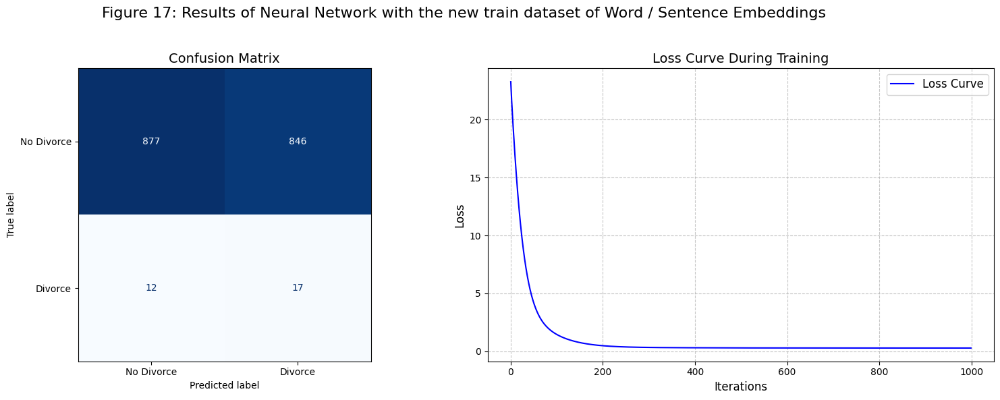

In [1012]:
# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Add a global title
fig.suptitle("Figure 17: Results of Neural Network with the new train dataset of Word / Sentence Embeddings", fontsize=16)

# First plot: Confusion Matrix
disp_nn = ConfusionMatrixDisplay(confusion_matrix=cm4, display_labels=['No Divorce', 'Divorce'])
disp_nn.plot(cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix", fontsize=14)

# Second plot: Loss Curve
axes[1].plot(clf_150_neurons_classification.loss_curve_, label="Loss Curve", color="blue")
axes[1].set_title("Loss Curve During Training", fontsize=14)
axes[1].set_xlabel("Iterations", fontsize=12)
axes[1].set_ylabel("Loss", fontsize=12)
axes[1].grid(True, linestyle="--", alpha=0.7)
axes[1].legend(fontsize=12)

# Adjust spacing between the plots
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for the global title

# Display the combined figure
plt.show()


## 9.2. Dataset of Bag of Words

### 9.2.1. Split data into Train / Test

In [1013]:
# Separate the data by the target class (txtDivorce)
y_train_1 = X_train2[y_train2 == 1]
y_train_0 = X_train2[y_train2 == 0]

# Calculate the number of samples needed for each class
num_ones = y_train_1.shape[0]
num_zeros = y_train_0.shape[0]

# Get 50% of the "1"s and "0"s
num_samples = min(num_ones, num_zeros) // 2

# Create the balanced dataset by taking equal numbers of "1"s and "0"s
X_new_train2 = pd.concat([y_train_1.sample(n=num_samples, random_state=666), y_train_0.sample(n=num_samples, random_state=666)])
y_new_train2 = pd.concat([y_train2[y_train2 == 1].sample(n=num_samples, random_state=666), y_train2[y_train2 == 0].sample(n=num_samples, random_state=666)])

# Shuffle the resulting dataset to ensure randomness
X_new_train2 = X_new_train2.sample(frac=1, random_state=666)
y_new_train2 = y_new_train2[X_new_train2.index]

# Check the size of the resulting dataset
print(f"Number of samples in the new training set: {X_new_train2.shape[0]}")
print(f"Number of 1s in y_new_train: {y_new_train2.sum()}")
print(f"Number of 0s in y_new_train: {len(y_new_train2) - y_new_train2.sum()}")


Number of samples in the new training set: 60
Number of 1s in y_new_train: 30.0
Number of 0s in y_new_train: 30.0


In [1014]:
# Get the indices of the data used in X_new_train
used_indices = X_new_train2.index

# Create the test sets with the remaining data
X_new_test2 = X_train2.drop(index=used_indices)
y_new_test2 = y_train2.drop(index=used_indices)

# Check the sizes to validate the separation
print(f"Number of samples in the new test set: {X_new_test2.shape[0]}")
print(f"Number of 1s in y_new_test: {y_new_test2.sum()}")
print(f"Number of 0s in y_new_test: {len(y_new_test2) - y_new_test2.sum()}")


Number of samples in the new test set: 1746
Number of 1s in y_new_test: 31.0
Number of 0s in y_new_test: 1715.0


### 9.2.2. Logistic regression with the new train dataset

In [1015]:
# Performing Logistic Regression
reg2 = LogisticRegression(max_iter = 10000)
reg2.fit(X_new_train2, y_new_train2)

coef = pd.Series(reg2.coef_.flatten(), index = X_new_train2.columns)

In [1016]:
# Test the logistic regression
y_new_pred2 = reg2.predict(X_new_test2)

In [1017]:
# Confusion matrix
cm5 = confusion_matrix(y_new_test2, y_new_pred2)
cm5_df = pd.DataFrame(cm5, index=['No Divorce', 'Divorce'], columns=['Predicted no divorce', 'Predicted divorce'])
print("Confusion Matrix:")
print(cm5_df)

Confusion Matrix:
            Predicted no divorce  Predicted divorce
No Divorce                  1709                  6
Divorce                       31                  0


In [1018]:
accuracy_score(y_new_test2, y_new_pred2)

0.9788087056128293

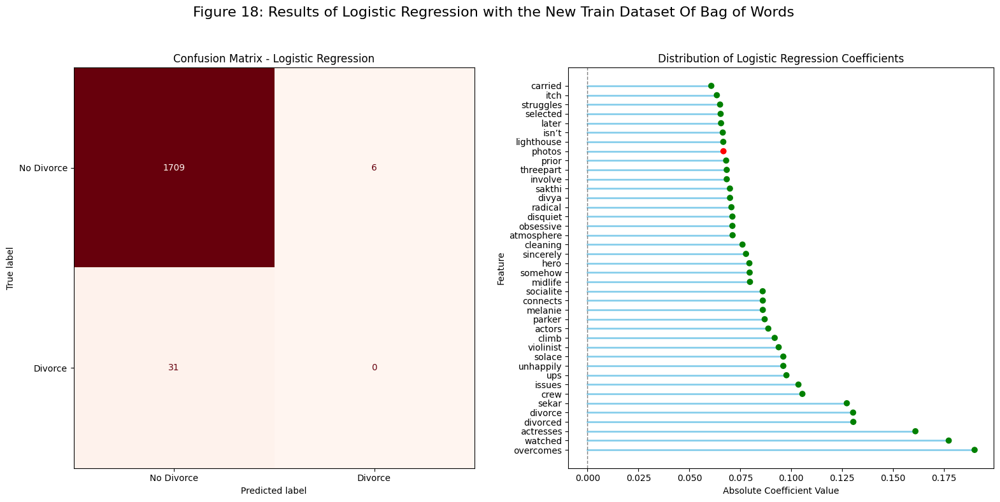

In [1019]:
# If X_new_train is a numpy array, manually provide feature names
feature_names = X_new_train2.columns if hasattr(X_new_train2, 'columns') else [f'Feature {i}' for i in range(X_new_train2.shape[1])]

# Extract coefficients from the logistic regression model
logistic_coefficients2 = pd.Series(reg2.coef_.flatten(), index=feature_names)

# Create the figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Add a global title to the panel
fig.suptitle("Figure 18: Results of Logistic Regression with the New Train Dataset Of Bag of Words", fontsize=16)

# 1st plot: Confusion Matrix
disp5 = ConfusionMatrixDisplay(confusion_matrix=cm5, display_labels=['No Divorce', 'Divorce'])
disp5.plot(cmap='Reds', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix - Logistic Regression")

# 2nd plot: Distribution of coefficients
plot_sorted_coefficients(logistic_coefficients2, axes[1], threshold=1e-08)
axes[1].set_title("Distribution of Logistic Regression Coefficients")

# Adjust spacing to leave space for the global title
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Display the combined figure
plt.show()


### 9.2.3. Neural Network with the new train dataset

In [1020]:
# Large Neural Network with three hidden layers ([100,50] neurons)
clf_150_neurons_classification2 = MLPClassifier(
    hidden_layer_sizes=(100, 50),  # Three hidden layers with 100 and 50 neurons respectively
    activation='relu',  # ReLU activation function
    solver='adam',  # Adam optimizer
    max_iter=1000,  # Max iterations for training
    alpha=10,  # Regularization parameter
    tol=1e-6,  # Tolerance for stopping criterion
    batch_size=1000,  # Batch size for training
    random_state=666,  # Random seed for reproducibility
    verbose=True  # Display training progress
)

# Train the network on the training data
clf_150_neurons_classification2.fit(X_new_train2, y_new_train2)

# Predict on the test set
y_new_pred2 = clf_150_neurons_classification2.predict(X_new_test2)

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:608: UserWarning: Got `batch_size` less than 1 or larger than sample size. It is going to be clipped
  warnings.warn(


Iteration 1, loss = 23.03434264
Iteration 2, loss = 20.98465864
Iteration 3, loss = 19.31179350
Iteration 4, loss = 17.81349889
Iteration 5, loss = 16.44083663
Iteration 6, loss = 15.17916268
Iteration 7, loss = 14.01965417
Iteration 8, loss = 12.95594854
Iteration 9, loss = 11.98281252
Iteration 10, loss = 11.09525276
Iteration 11, loss = 10.28806246
Iteration 12, loss = 9.55618358
Iteration 13, loss = 8.89443076
Iteration 14, loss = 8.29780288
Iteration 15, loss = 7.76139538
Iteration 16, loss = 7.28063745
Iteration 17, loss = 6.85099088
Iteration 18, loss = 6.46805532
Iteration 19, loss = 6.12753558
Iteration 20, loss = 5.82531860
Iteration 21, loss = 5.55749703
Iteration 22, loss = 5.32038216
Iteration 23, loss = 5.11053297
Iteration 24, loss = 4.92469924
Iteration 25, loss = 4.75990486
Iteration 26, loss = 4.61341824
Iteration 27, loss = 4.48266947
Iteration 28, loss = 4.36541700
Iteration 29, loss = 4.25958137
Iteration 30, loss = 4.16334568
Iteration 31, loss = 4.07511800
Iterat

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [1021]:
# Confusion matrix
cm6 = confusion_matrix(y_new_test2, y_new_pred2)
cm6_df = pd.DataFrame(cm6, index=['Divorce', 'No Divorce'], columns=['Predicted Divrorce', 'Predicted No Divorce'])
print("Confusion Matrix:")
print(cm6_df)

Confusion Matrix:
            Predicted Divrorce  Predicted No Divorce
Divorce                   1696                    19
No Divorce                  30                     1


In [1022]:
accuracy_score(y_new_test2, y_new_pred2)

0.9719358533791523

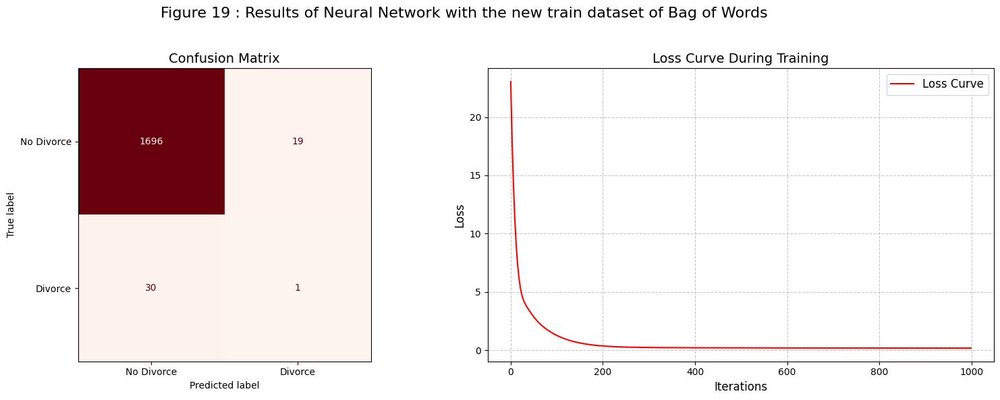

In [1023]:
# Create a figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Add a global title
fig.suptitle("Figure 19 : Results of Neural Network with the new train dataset of Bag of Words", fontsize=16)

# First plot: Confusion Matrix
disp_nn = ConfusionMatrixDisplay(confusion_matrix=cm6, display_labels=['No Divorce', 'Divorce'])
disp_nn.plot(cmap='Reds', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix", fontsize=14)

# Second plot: Loss Curve
axes[1].plot(clf_150_neurons_classification2.loss_curve_, label="Loss Curve", color="red")
axes[1].set_title("Loss Curve During Training", fontsize=14)
axes[1].set_xlabel("Iterations", fontsize=12)
axes[1].set_ylabel("Loss", fontsize=12)
axes[1].grid(True, linestyle="--", alpha=0.7)
axes[1].legend(fontsize=12)

# Adjust the spacing between the plots
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for the global title

# Show the combined figure
plt.show()


# 10. DIAGNOSTIC OF THE MODELS WITH THE NEW TRAIN DATASET

## 10.1. Diagnostic of the Word / Sentence Embeddings with the new train dataset

### 10.1.1. Diagnostic of the logistic regression (recall)

In [1024]:
# Models
models_E = {
    "logistic_regression": reg  # Logistic regression model
}

# Datasets
datasets_E = {
    "test": (X_new_test, y_new_test),
    "train": (X_new_train, y_new_train)
}

# Initialize dictionaries for storing metrics
accuracies_E = {}
recalls_E = {}

# Calculate metrics for each model and dataset
for model_name, model in models_E.items():
    for dataset_name, (X, y) in datasets_E.items():
        # Predict using the model
        y_pred = model.predict(X)

        # Calculate accuracy
        acc_key = f"acc_{dataset_name}_{model_name}_E"
        accuracies_E[acc_key] = accuracy_score(y, y_pred)

        # Calculate recall
        recall_key = f"recall_{dataset_name}_{model_name}_E"
        recalls_E[recall_key] = recall_score(y, y_pred, average='binary')  # Use 'binary' for binary classification

# Map model keys to formatted names for the DataFrame
model_name_map = {
    "logistic_regression": "Logistic Regression"
}

# Create a structured dictionary for results
data_results_E = {'Train/Test': [], 'Model': [], 'Accuracy': [], 'Recall': []}
for model_key, model_name in model_name_map.items():
    for dataset_name in datasets_E.keys():
        acc_key = f"acc_{dataset_name}_{model_key}_E"
        recall_key = f"recall_{dataset_name}_{model_key}_E"

        # Retrieve values from the populated dictionaries
        data_results_E['Train/Test'].append(dataset_name)
        data_results_E['Model'].append(model_name)
        data_results_E['Accuracy'].append(accuracies_E[acc_key])
        data_results_E['Recall'].append(recalls_E[recall_key])

# Create the DataFrame
df_results_E = pd.DataFrame(data_results_E)

# Ensure consistent order for 'Model' column
model_order = ['Logistic Regression']
df_results_E['Model'] = pd.Categorical(df_results_E['Model'], categories=model_order, ordered=True)

# Pivot table for Accuracy
df_pivot_E = df_results_E.pivot(index='Model', columns='Train/Test', values='Accuracy')
df_pivot_E['Accuracy Difference (Train - Test)'] = df_pivot_E['train'] - df_pivot_E['test']

# Pivot table for Recall
df_pivot_recall_E = df_results_E.pivot(index='Model', columns='Train/Test', values='Recall')
df_pivot_recall_E['Recall Difference (Train - Test)'] = df_pivot_recall_E['train'] - df_pivot_recall_E['test']

# Display both tables
print("\nAccuracy Table:")
print(df_pivot_E)

print("\nRecall Table:")
print(df_pivot_recall_E)


Accuracy Table:
Train/Test               test  train  Accuracy Difference (Train - Test)
Model                                                                   
Logistic Regression  0.518836    1.0                            0.481164

Recall Table:
Train/Test               test  train  Recall Difference (Train - Test)
Model                                                                 
Logistic Regression  0.586207    1.0                          0.413793


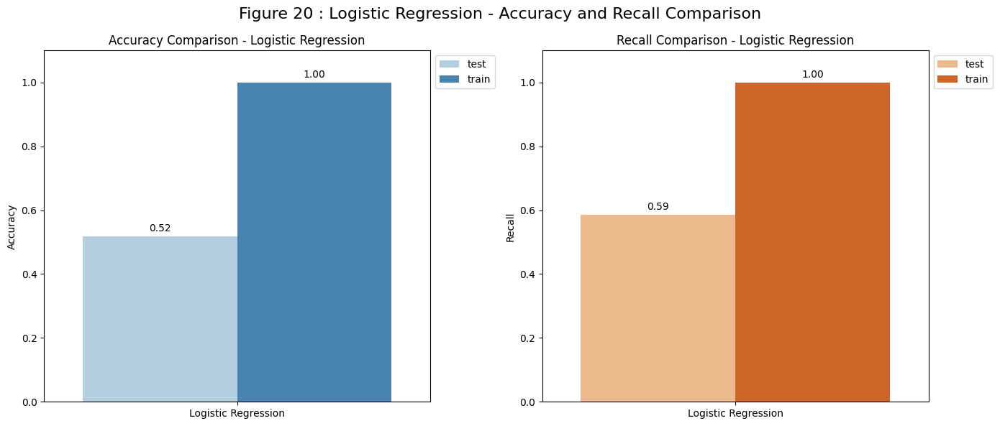

In [1025]:
# Create the figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define model order for Logistic Regression (model E)
model_order = ['Logistic Regression']

# Plot 1: Accuracy Comparison for Logistic Regression (model E)
sns.barplot(
    ax=axes[0],
    x='Model',
    y='Accuracy',
    hue='Train/Test',
    data=df_results_E,  # Using df_results_E with recall metrics
    order=model_order,
    palette='Blues'
)

# Add annotations to the bars for accuracy
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[0].set_title('Accuracy Comparison - Logistic Regression')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Plot 2: Recall Comparison for Logistic Regression (model E)
sns.barplot(
    ax=axes[1],
    x='Model',
    y='Recall',
    hue='Train/Test',
    data=df_results_E,  # Using df_results_E with recall metrics
    order=model_order,
    palette='Oranges'
)

# Add annotations to the bars for recall
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[1].set_title('Recall Comparison - Logistic Regression')
axes[1].set_ylabel('Recall')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Add a main title for the figure
fig.suptitle('Figure 20 : Logistic Regression - Accuracy and Recall Comparison', fontsize=16)

# Adjust spacing to avoid overlap
plt.tight_layout()
plt.show()


### 10.1.2. Diagnostic of the Neural Network (recall)

In [1026]:
# Models
models_F = {
    "neural_network": clf_150_neurons_classification  # Large Neural Network with 3 hidden layers
}

# Datasets
datasets_F = {
    "test": (X_new_test, y_new_test),
    "train": (X_new_train, y_new_train)
}

# Initialize dictionaries for storing metrics
accuracies_F = {}
recalls_F = {}

# Calculate metrics for each model and dataset
for model_name, model in models_F.items():
    for dataset_name, (X, y) in datasets_F.items():
        # Predict using the model
        y_pred = model.predict(X)

        # Calculate accuracy
        acc_key = f"acc_{dataset_name}_{model_name}_F"
        accuracies_F[acc_key] = accuracy_score(y, y_pred)

        # Calculate recall
        recall_key = f"recall_{dataset_name}_{model_name}_F"
        recalls_F[recall_key] = recall_score(y, y_pred, average='binary')  # Use 'binary' for binary classification

# Map model keys to formatted names for the DataFrame
model_name_map = {
    "neural_network": "Neural Network"
}

# Create a structured dictionary for results
data_results_F = {'Train/Test': [], 'Model': [], 'Accuracy': [], 'Recall': []}
for model_key, model_name in model_name_map.items():
    for dataset_name in datasets_F.keys():
        acc_key = f"acc_{dataset_name}_{model_key}_F"
        recall_key = f"recall_{dataset_name}_{model_key}_F"

        # Retrieve values from the populated dictionaries
        data_results_F['Train/Test'].append(dataset_name)
        data_results_F['Model'].append(model_name)
        data_results_F['Accuracy'].append(accuracies_F[acc_key])
        data_results_F['Recall'].append(recalls_F[recall_key])

# Create the DataFrame
df_results_F = pd.DataFrame(data_results_F)

# Ensure consistent order for 'Model' column
model_order = ['Neural Network']
df_results_F['Model'] = pd.Categorical(df_results_F['Model'], categories=model_order, ordered=True)

# Pivot table for Accuracy
df_pivot_F = df_results_F.pivot(index='Model', columns='Train/Test', values='Accuracy')
df_pivot_F['Accuracy Difference (Train - Test)'] = df_pivot_F['train'] - df_pivot_F['test']

# Pivot table for Recall
df_pivot_recall_F = df_results_F.pivot(index='Model', columns='Train/Test', values='Recall')
df_pivot_recall_F['Recall Difference (Train - Test)'] = df_pivot_recall_F['train'] - df_pivot_recall_F['test']

print("\nAccuracy Table:")
print(df_pivot_F)

print("\nRecall Table:")
print(df_pivot_recall_F)




Accuracy Table:
Train/Test          test  train  Accuracy Difference (Train - Test)
Model                                                              
Neural Network  0.510274    1.0                            0.489726

Recall Table:
Train/Test          test  train  Recall Difference (Train - Test)
Model                                                            
Neural Network  0.586207    1.0                          0.413793


<ipython-input-1027-3ce71ff48f20>:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])  # Example models, adjust as necessary
<ipython-input-1027-3ce71ff48f20>:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])  # Example models, adjust as necessary


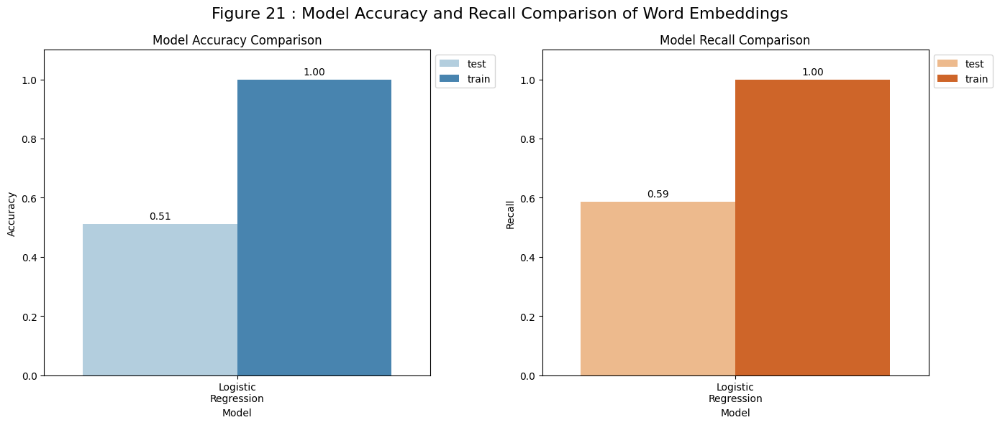

In [1027]:
# Ensure that 'Accuracy' and 'Recall' columns are numeric
df_results_F['Accuracy'] = pd.to_numeric(df_results_F['Accuracy'], errors='coerce')
df_results_F['Recall'] = pd.to_numeric(df_results_F['Recall'], errors='coerce')

# Reset the index to avoid any indexing issues
df_results_F = df_results_F.reset_index(drop=True)

# Create the figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Model Accuracy Comparison (for Model F)
sns.barplot(ax=axes[0], x='Model', y='Accuracy', hue='Train/Test', data=df_results_F, order=model_order, palette='Blues')

# Add annotations to the bars for accuracy
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[0].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])  # Example models, adjust as necessary
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))
axes[0].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[0].set_title('Model Accuracy Comparison')
axes[0].set_ylabel('Accuracy')

# Plot 2: Model Recall Comparison (for Model F)
sns.barplot(ax=axes[1], x='Model', y='Recall', hue='Train/Test', data=df_results_F, order=model_order, palette='Oranges')

# Add annotations to the bars for recall
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[1].set_xticklabels(['Logistic\nRegression', 'Neural\nNetwork'])  # Example models, adjust as necessary
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
axes[1].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[1].set_title('Model Recall Comparison')
axes[1].set_ylabel('Recall')

# Add a main title for the figure
fig.suptitle('Figure 21 : Model Accuracy and Recall Comparison of Word Embeddings', fontsize=16)

# Adjust spacing to avoid overlap
plt.tight_layout()
plt.show()


## 10.2. Diagnostic of the Bag of Words with the new train dataset




### 10.2.1. Diagnostic of the logistic regression (recall)

In [1028]:
# Models
models_G = {
    "logistic_regression": reg2  # Logistic regression model (model G)
}

# Datasets
datasets_G = {
    "test": (X_new_test2, y_new_test2),  # Use the new test dataset
    "train": (X_new_train2, y_new_train2)  # Use the new train dataset
}

# Initialize dictionaries for storing metrics
accuracies_G = {}
recalls_G = {}

# Calculate metrics for each model and dataset
for model_name, model in models_G.items():
    for dataset_name, (X, y) in datasets_G.items():
        # Predict using the model
        y_pred = model.predict(X)

        # Calculate accuracy
        acc_key = f"acc_{dataset_name}_{model_name}_G"
        accuracies_G[acc_key] = accuracy_score(y, y_pred)

        # Calculate recall
        recall_key = f"recall_{dataset_name}_{model_name}_G"
        recalls_G[recall_key] = recall_score(y, y_pred, average='binary')  # Use 'binary' for binary classification

# Map model keys to formatted names for the DataFrame
model_name_map = {
    "logistic_regression": "Logistic Regression"
}

# Create a structured dictionary for results
data_results_G = {'Train/Test': [], 'Model': [], 'Accuracy': [], 'Recall': []}
for model_key, model_name in model_name_map.items():
    for dataset_name in datasets_G.keys():
        acc_key = f"acc_{dataset_name}_{model_key}_G"
        recall_key = f"recall_{dataset_name}_{model_key}_G"

        # Retrieve values from the populated dictionaries
        data_results_G['Train/Test'].append(dataset_name)
        data_results_G['Model'].append(model_name)
        data_results_G['Accuracy'].append(accuracies_G[acc_key])
        data_results_G['Recall'].append(recalls_G[recall_key])

# Create the DataFrame
df_results_G = pd.DataFrame(data_results_G)

# Ensure consistent order for 'Model' column
model_order = ['Logistic Regression']
df_results_G['Model'] = pd.Categorical(df_results_G['Model'], categories=model_order, ordered=True)

# Pivot table for Accuracy for Model G
df_pivot_G_accuracy = df_results_G.pivot(index='Model', columns='Train/Test', values='Accuracy')
df_pivot_G_accuracy['Accuracy Difference (Train - Test)'] = df_pivot_G_accuracy['train'] - df_pivot_G_accuracy['test']

# Pivot table for Recall for Model G
df_pivot_G_recall = df_results_G.pivot(index='Model', columns='Train/Test', values='Recall')
df_pivot_G_recall['Recall Difference (Train - Test)'] = df_pivot_G_recall['train'] - df_pivot_G_recall['test']

# Display both tables
print("\nAccuracy Table for Model G:")
print(df_pivot_G_accuracy)

print("\nRecall Table for Model G:")
print(df_pivot_G_recall)



Accuracy Table for Model G:
Train/Test               test  train  Accuracy Difference (Train - Test)
Model                                                                   
Logistic Regression  0.978809    1.0                            0.021191

Recall Table for Model G:
Train/Test           test  train  Recall Difference (Train - Test)
Model                                                             
Logistic Regression   0.0    1.0                               1.0


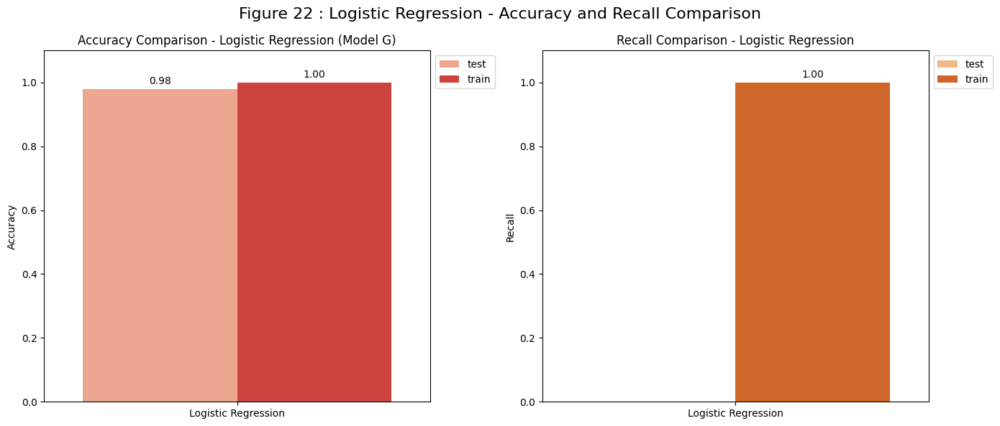

In [1029]:
# Create the figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define model order for Logistic Regression (model G)
model_order = ['Logistic Regression']

# Plot 1: Accuracy Comparison for Logistic Regression (model G)
sns.barplot(
    ax=axes[0],
    x='Model',
    y='Accuracy',
    hue='Train/Test',
    data=df_results_G,  # Using df_results_G with accuracy metrics for model G
    order=model_order,
    palette='Reds'
)

# Add annotations to the bars for accuracy
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[0].set_title('Accuracy Comparison - Logistic Regression (Model G)')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Plot 2: Recall Comparison for Logistic Regression (model G)
sns.barplot(
    ax=axes[1],
    x='Model',
    y='Recall',
    hue='Train/Test',
    data=df_results_G,  # Using df_results_G with recall metrics for model G
    order=model_order,
    palette='Oranges'
)

# Add annotations to the bars for recall
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[1].set_title('Recall Comparison - Logistic Regression')
axes[1].set_ylabel('Recall')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 1.1)  # Extend y-axis slightly
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Add a main title for the figure
fig.suptitle('Figure 22 : Logistic Regression - Accuracy and Recall Comparison', fontsize=16)

# Adjust spacing to avoid overlap
plt.tight_layout()
plt.show()


### 10.2.2. Diagnostic of the neural network (recall)

In [1030]:
# Models
models_G = {
    "neural_network": clf_150_neurons_classification2  # Large Neural Network with 3 hidden layers (100, 50 neurons)
}

# Datasets
datasets_G = {
    "test": (X_new_test2, y_new_test2),
    "train": (X_new_train2, y_new_train2)
}

# Initialize dictionaries for storing metrics
accuracies_G = {}
recalls_G = {}

# Calculate metrics for each model and dataset
for model_name, model in models_G.items():
    for dataset_name, (X, y) in datasets_G.items():
        # Predict using the model
        y_pred = model.predict(X)

        # Calculate accuracy
        acc_key = f"acc_{dataset_name}_{model_name}_G"
        accuracies_G[acc_key] = accuracy_score(y, y_pred)

        # Calculate recall
        recall_key = f"recall_{dataset_name}_{model_name}_G"
        recalls_G[recall_key] = recall_score(y, y_pred, average='binary')  # Use 'binary' for binary classification

# Map model keys to formatted names for the DataFrame
model_name_map = {
    "neural_network": "Neural Network"
}

# Create a structured dictionary for results
data_results_G = {'Train/Test': [], 'Model': [], 'Accuracy': [], 'Recall': []}
for model_key, model_name in model_name_map.items():
    for dataset_name in datasets_G.keys():
        acc_key = f"acc_{dataset_name}_{model_key}_G"
        recall_key = f"recall_{dataset_name}_{model_key}_G"

        # Retrieve values from the populated dictionaries
        data_results_G['Train/Test'].append(dataset_name)
        data_results_G['Model'].append(model_name)
        data_results_G['Accuracy'].append(accuracies_G[acc_key])
        data_results_G['Recall'].append(recalls_G[recall_key])

# Create the DataFrame
df_results_G = pd.DataFrame(data_results_G)

# Ensure consistent order for 'Model' column
model_order = ['Neural Network']
df_results_G['Model'] = pd.Categorical(df_results_G['Model'], categories=model_order, ordered=True)

# Pivot table for Accuracy
df_pivot_G = df_results_G.pivot(index='Model', columns='Train/Test', values='Accuracy')
df_pivot_G['Accuracy Difference (Train - Test)'] = df_pivot_G['train'] - df_pivot_G['test']

# Pivot table for Recall
df_pivot_recall_G = df_results_G.pivot(index='Model', columns='Train/Test', values='Recall')
df_pivot_recall_G['Recall Difference (Train - Test)'] = df_pivot_recall_G['train'] - df_pivot_recall_G['test']

# Display both tables
print("\nAccuracy Table:")
print(df_pivot_G)

print("\nRecall Table:")
print(df_pivot_recall_G)



Accuracy Table:
Train/Test          test  train  Accuracy Difference (Train - Test)
Model                                                              
Neural Network  0.971936    1.0                            0.028064

Recall Table:
Train/Test          test  train  Recall Difference (Train - Test)
Model                                                            
Neural Network  0.032258    1.0                          0.967742


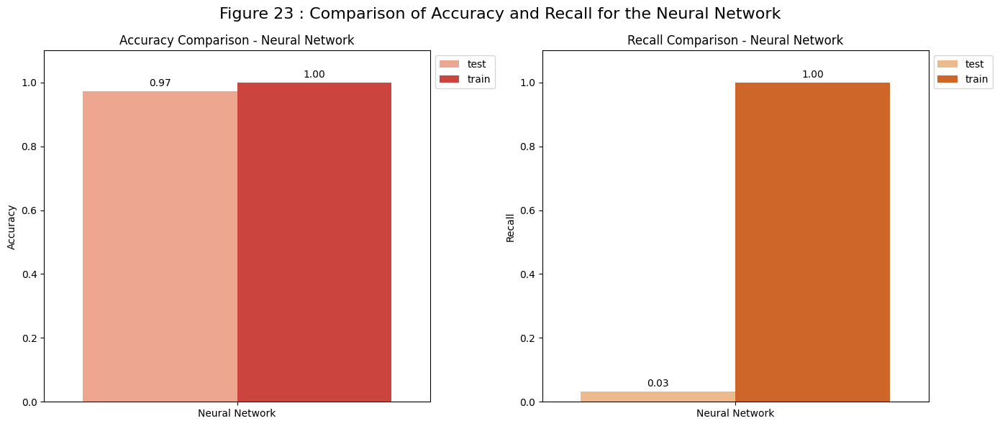

In [1031]:
# Ensure that the 'Accuracy' and 'Recall' columns are numeric
df_results_G['Accuracy'] = pd.to_numeric(df_results_G['Accuracy'], errors='coerce')
df_results_G['Recall'] = pd.to_numeric(df_results_G['Recall'], errors='coerce')

# Reset the index to avoid any indexing issues
df_results_G = df_results_G.reset_index(drop=True)

# Create the figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define the model order for comparison
model_order = ['Neural Network']

# Plot 1: Accuracy Comparison for Model G
sns.barplot(
    ax=axes[0],
    x='Model',
    y='Accuracy',
    hue='Train/Test',
    data=df_results_G,  # Using the results of Model G
    order=model_order,
    palette='Reds'
)

# Add annotations to the bars for accuracy
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[0].set_title('Accuracy Comparison - Neural Network')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 1.1)  # Adjust the y-axis scale slightly above 1
axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Plot 2: Recall Comparison for Model G
sns.barplot(
    ax=axes[1],
    x='Model',
    y='Recall',
    hue='Train/Test',
    data=df_results_G,  # Using the results of Model G
    order=model_order,
    palette='Oranges'
)

# Add annotations to the bars for recall
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', xytext=(0, 5), textcoords='offset points')

axes[1].set_title('Recall Comparison - Neural Network')
axes[1].set_ylabel('Recall')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 1.1)  # Adjust the y-axis scale slightly above 1
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))

# Add a main title for the figure
fig.suptitle('Figure 23 : Comparison of Accuracy and Recall for the Neural Network', fontsize=16)

# Adjust spacing to avoid overlap
plt.tight_layout()
plt.show()


# 11. RESULTS

## 11.1. Performance table with whole of our models

### 11.1.1 Dataset of Words / Sentence Embeddings

In [1032]:
# Dictionary to store the metrics
data = {
    "Model": [
        "Logistic Regression",
        "Neural Network",
        "Lasso Logistic Regression",
        "Neural Network Adjusted",
        "Logistic Regression New Train",
        "Neural Network New Train"
    ],
    "Test Accuracy": [0.942, 0.956, 0.958, 0.956, 0.519, 0.510],
    "Train Accuracy": [1, 1, 0.968, 0.968, 1, 1],
    "Test Recall": [0.158, 0, 0, 0, 0.586, 0.586],
    "Train Recall": [1, 1, 0, 0, 1, 1]
}

# Create the DataFrame
performance_df2 = pd.DataFrame(data)

# Display the table
print("Figure 23. Results table for the different models using Words / Sentence embeddings:\n")
print(performance_df2)

Figure 23. Results table for the different models using Words / Sentence embeddings:

                           Model  Test Accuracy  Train Accuracy  Test Recall  Train Recall
0            Logistic Regression          0.942           1.000        0.158             1
1                 Neural Network          0.956           1.000        0.000             1
2      Lasso Logistic Regression          0.958           0.968        0.000             0
3        Neural Network Adjusted          0.956           0.968        0.000             0
4  Logistic Regression New Train          0.519           1.000        0.586             1
5       Neural Network New Train          0.510           1.000        0.586             1


### 11.1.2. Dataset of Bag of Words

In [1033]:
# Dictionary to store the metrics
data = {
    "Model": [
        "Logistic Regression",
        "Neural Network",
        "Lasso Logistic Regression",
        "Neural Network Adjusted",
        "Logistic Regression New Train",
        "Neural Network New Train"
    ],
    "Test Accuracy": [0.967, 0.967, 0.967, 0.701, 0.979, 0.972],
    "Train Accuracy": [1, 1, 0.967, 0.927, 1, 1],
    "Test Recall": [0, 0, 0, 0.333, 0, 0.032],
    "Train Recall": [0.49, 0.51, 0.016, 0.475, 1, 1]
}

# Create the DataFrame
performance_df = pd.DataFrame(data)

# Display the table
print("Figure 24. Results table for the different models using Bag of Words:\n")
print(performance_df)

Figure 24. Results table for the different models using Bag of Words:

                           Model  Test Accuracy  Train Accuracy  Test Recall  Train Recall
0            Logistic Regression          0.967           1.000        0.000         0.490
1                 Neural Network          0.967           1.000        0.000         0.510
2      Lasso Logistic Regression          0.967           0.967        0.000         0.016
3        Neural Network Adjusted          0.701           0.927        0.333         0.475
4  Logistic Regression New Train          0.979           1.000        0.000         1.000
5       Neural Network New Train          0.972           1.000        0.032         1.000


# 12. CONCLUSION

Despite our various attempts to improve the recall of our different algorithms (adjusted models and new train dataset), the variance problem persists (see Figure 23 and 24) ; the ratio between the number of divorces and non-divorces is too high and our algorithms prefer to predict non-divorces rather than divorces in order to maximize accuracy.

In order to improve recall, we should have more films containing a divorce to better train our algorithms or have more relevant features.

However, we should note that the highest recall and most consistent between the recall test and train for the dataset of the bag of words is the Neural Network Adjusted (Recall test of 0.333 and recall train of 0.475). For the word/sentence embeddings dataset, the highest and most consistent recall between train and test is that of logistic regression and neural network, both with the new training dataset with equal proportion between divorce and non-divorce (recall test of 0.586 and recall train of 1).